In [1]:
import pandas as pd
import numpy as np
import requests
import seaborn as sns
import matplotlib.pyplot as plt
import re
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, kruskal
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import f_oneway
import os

In [2]:
MAIN_FILE = "PythonStepProject"

def save_markdown(df, rows=None, tablefmt="grid"):
    """
    Зберігання DataFrame в Markdown-файл.
    Ім"я файлу формується на основі MAIN_FILE + індекс.
    """

    # пошук вільного індексу
    i = 1
    while True:
        filename = f"{MAIN_FILE}_{i}.md"
        if not os.path.exists(filename):
            break
        i += 1

    # обмеження строк, якщо потрібно
    df_to_save = df.head(rows) if rows else df

    # форматування markdown
    content = df_to_save.to_markdown(tablefmt=tablefmt)

    with open(filename, "w", encoding="utf-8") as f:
        f.write(content)

    print(f"✅ Збережено у файл: {filename}")

In [3]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-11-03/ikea.csv"

In [4]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-11-03/ikea.csv"
response = requests.get(URL)
if response.status_code == 200:
    df = pd.read_csv(URL)
    print(f"Дані успішно завантажені!")
else:
    print(f"Помилка завантаження: status_code = {response.status_code}")

Дані успішно завантажені!


In [5]:
df

,Unnamed: 0,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width
0,0,90420332,FREKVENS,Bar furniture,265.0,No old price,True,https://www.ikea.com/sa/en/p/frekvens-bar-tabl...,No,"Bar table, in/outdoor, 51x51 cm",Nicholai Wiig Hansen,NaN,99.0,51.0
1,1,368814,NORDVIKEN,Bar furniture,995.0,No old price,False,https://www.ikea.com/sa/en/p/nordviken-bar-tab...,No,"Bar table, 140x80 cm",Francis Cayouette,NaN,105.0,80.0
2,2,9333523,NORDVIKEN / NORDVIKEN,Bar furniture,2095.0,No old price,False,https://www.ikea.com/sa/en/p/nordviken-nordvik...,No,Bar table and 4 bar stools,Francis Cayouette,NaN,NaN,NaN
3,3,80155205,STIG,Bar furniture,69.0,No old price,True,https://www.ikea.com/sa/en/p/stig-bar-stool-wi...,Yes,"Bar stool with backrest, 74 cm",Henrik Preutz,50.0,100.0,60.0
4,4,30180504,NORBERG,Bar furniture,225.0,No old price,True,https://www.ikea.com/sa/en/p/norberg-wall-moun...,No,"Wall-mounted drop-leaf table, ...",Marcus Arvonen,60.0,43.0,74.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3689,3689,99157902,ELVARLI,Wardrobes,750.0,SR 820,True,https://www.ikea.com/sa/en/p/elvarli-1-section...,No,"1 section, 92x51x222-350 cm",Ehlén Johansson,50.0,NaN,91.0
3690,3690,9158152,ELVARLI,Wardrobes,1572.0,"SR 1,755",True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 135x51x222-350 cm",Ehlén Johansson,50.0,NaN,135.0
3691,3691,59157541,ELVARLI,Wardrobes,924.0,"SR 1,050",True,https://www.ikea.com/sa/en/p/elvarli-2-section...,No,"2 sections, 175x51x222-350 cm",Ehlén Johansson,50.0,NaN,175.0
3692,3692,89157573,ELVARLI,Wardrobes,2745.0,"SR 3,130",True,https://www.ikea.com/sa/en/p/elvarli-3-section...,No,"3 sections, 178x51x222-350 cm",Ehlén Johansson,50.0,NaN,178.0


In [6]:
df.shape

(3694, 14)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3694 entries, 0 to 3693
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         3694 non-null   int64  
 1   item_id            3694 non-null   int64  
 2   name               3694 non-null   str    
 3   category           3694 non-null   str    
 4   price              3694 non-null   float64
 5   old_price          3694 non-null   str    
 6   sellable_online    3694 non-null   bool   
 7   link               3694 non-null   str    
 8   other_colors       3694 non-null   str    
 9   short_description  3694 non-null   str    
 10  designer           3694 non-null   str    
 11  depth              2231 non-null   float64
 12  height             2706 non-null   float64
 13  width              3105 non-null   float64
dtypes: bool(1), float64(4), int64(2), str(7)
memory usage: 378.9 KB


In [8]:
df.describe()

,Unnamed: 0,item_id,price,depth,height,width
count,3694.000000,3.694000e+03,3694.000000,2231.000000,2706.000000,3105.000000
mean,1846.500000,4.863240e+07,1078.208419,54.379202,101.679970,104.470853
std,1066.510275,2.888709e+07,1374.652494,29.958351,61.097585,71.133771
min,0.000000,5.848700e+04,3.000000,1.000000,1.000000,1.000000
25%,923.250000,2.039057e+07,180.900000,38.000000,67.000000,60.000000
50%,1846.500000,4.928808e+07,544.700000,47.000000,83.000000,80.000000
75%,2769.750000,7.040357e+07,1429.500000,60.000000,124.000000,140.000000
max,3693.000000,9.993262e+07,9585.000000,257.000000,700.000000,420.000000


In [9]:
df.describe(include="str")

,name,category,old_price,link,other_colors,short_description,designer
count,3694,3694,3694,3694,3694,3694,3694
unique,607,17,365,2962,2,1706,381
top,BESTÅ,Tables & desks,No old price,https://www.ikea.com/sa/en/p/norraker-norraker...,No,Chair,IKEA of Sweden
freq,173,612,3040,4,2182,59,828


In [10]:
df.nunique()

Unnamed: 0           3694
item_id              2962
name                  607
category               17
price                 979
old_price             365
sellable_online         2
link                 2962
other_colors            2
short_description    1706
designer              381
depth                 114
height                193
width                 263
dtype: int64

In [11]:
df =df.drop(columns="Unnamed: 0")

In [12]:
df["category"].value_counts()

category
Tables & desks                          612
Bookcases & shelving units              548
Chairs                                  481
Sofas & armchairs                       428
Cabinets & cupboards                    292
Wardrobes                               236
Outdoor furniture                       216
Beds                                    208
TV & media furniture                    190
Chests of drawers & drawer units        125
Children's furniture                    124
Nursery furniture                        97
Bar furniture                            47
Trolleys                                 28
Café furniture                           26
Sideboards, buffets & console tables     23
Room dividers                            13
Name: count, dtype: int64

In [13]:
df.sort_values("price", ascending=False).max()

item_id                                                       99932615
name                                                 ÖVRARYD / JANINGE
category                                                     Wardrobes
price                                                           9585.0
old_price                                                       SR 995
sellable_online                                                   True
link                 https://www.ikea.com/sa/en/p/ytteroen-seat-bac...
other_colors                                                       Yes
short_description                  Work bench,          120x63.5x92 cm
designer                                                Wiebke Braasch
depth                                                            257.0
height                                                           700.0
width                                                            420.0
dtype: object

In [14]:
df[df.duplicated(subset=["item_id"], keep=False)].sort_values(by="item_id")

,item_id,name,category,price,old_price,sellable_online,link,other_colors,short_description,designer,depth,height,width
1918,91415,TROFAST,Nursery furniture,5.0,No old price,True,https://www.ikea.com/sa/en/p/trofast-lid-white...,No,"Lid, 20x28 cm",Studio Copenhagen,NaN,NaN,28.0
1834,91415,TROFAST,Children's furniture,5.0,No old price,True,https://www.ikea.com/sa/en/p/trofast-lid-white...,No,"Lid, 20x28 cm",Studio Copenhagen,NaN,NaN,28.0
2560,102065,LYCKSELE LÖVÅS,Sofas & armchairs,495.0,No old price,True,https://www.ikea.com/sa/en/p/lycksele-loevas-m...,No,"Mattress, 140x188 cm",IKEA of Sweden,NaN,NaN,NaN
151,102065,LYCKSELE LÖVÅS,Beds,495.0,No old price,True,https://www.ikea.com/sa/en/p/lycksele-loevas-m...,No,"Mattress, 140x188 cm",IKEA of Sweden,NaN,NaN,NaN
2178,105064,LIATORP,"Sideboards, buffets & console tables",445.0,No old price,True,https://www.ikea.com/sa/en/p/liatorp-console-t...,No,"Console table, 133x37 cm",Carina Bengs,NaN,75.0,37.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2860,99323614,SMÅGÖRA,Tables & desks,370.0,No old price,True,https://www.ikea.com/sa/en/p/smagoera-changing...,No,Changing tbl/bookshelf w 1 shlf ut,IKEA of Sweden,40.0,91.0,60.0
29,99323925,STENSELE,Bar furniture,550.0,No old price,True,https://www.ikea.com/sa/en/p/stensele-bar-tabl...,No,"Bar table, 70x70 cm",Maja Ganszyniec,NaN,104.0,70.0
3028,99323925,STENSELE,Tables & desks,550.0,No old price,True,https://www.ikea.com/sa/en/p/stensele-bar-tabl...,No,"Bar table, 70x70 cm",Maja Ganszyniec,NaN,104.0,70.0
409,99902661,VITTSJÖ,Bookcases & shelving units,609.0,No old price,True,https://www.ikea.com/sa/en/p/vittsjoe-shelving...,No,"Shelving unit with laptop table, ...",Johan Kroon,36.0,NaN,202.0


In [15]:
print(f"df = {len(df)}")

df = 3694


In [16]:
df_unique = df.drop_duplicates(subset=["item_id"]).copy()

In [17]:
print(f"df_unique = {len(df_unique)}")

df_unique = 2962


In [18]:
df_unique.info()

<class 'pandas.DataFrame'>
Index: 2962 entries, 0 to 3692
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   item_id            2962 non-null   int64  
 1   name               2962 non-null   str    
 2   category           2962 non-null   str    
 3   price              2962 non-null   float64
 4   old_price          2962 non-null   str    
 5   sellable_online    2962 non-null   bool   
 6   link               2962 non-null   str    
 7   other_colors       2962 non-null   str    
 8   short_description  2962 non-null   str    
 9   designer           2962 non-null   str    
 10  depth              1844 non-null   float64
 11  height             2236 non-null   float64
 12  width              2520 non-null   float64
dtypes: bool(1), float64(4), int64(1), str(7)
memory usage: 303.7 KB


In [19]:
df_unique = df_unique.drop(columns=["link"])

In [20]:
df_unique.info()

<class 'pandas.DataFrame'>
Index: 2962 entries, 0 to 3692
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   item_id            2962 non-null   int64  
 1   name               2962 non-null   str    
 2   category           2962 non-null   str    
 3   price              2962 non-null   float64
 4   old_price          2962 non-null   str    
 5   sellable_online    2962 non-null   bool   
 6   other_colors       2962 non-null   str    
 7   short_description  2962 non-null   str    
 8   designer           2962 non-null   str    
 9   depth              1844 non-null   float64
 10  height             2236 non-null   float64
 11  width              2520 non-null   float64
dtypes: bool(1), float64(4), int64(1), str(6)
memory usage: 280.6 KB


In [21]:
df_unique["designer"].value_counts().count()

np.int64(381)

In [22]:
df_unique["designer"].value_counts(ascending=True)

designer
Nike Karlsson/Maja Ganszyniec                                                                                                                                                                                                                                                                                                                                                                                            1
IKEA of Sweden/Karl Malmvall                                                                                                                                                                                                                                                                                                                                                                                             1
504.689.53 Small and easy-to-place chair-bed which can easily be converted into a single bed.The storage space under the seat has room for bedlinen or other things.Just 

In [23]:
df_designers = df_unique.copy()

In [24]:
print(f"df_designers = {len(df_designers)}")

df_designers = 2962


In [25]:
mask = df_designers["designer"].astype(str).str.match(r"^\d") & \
       (df_designers["designer"].astype(str).str.len() > 60)
df_designers.loc[mask, "designer"]

51      504.689.53 Small and easy-to-place chair-bed w...
77      903.310.91 The door can be hung with the openi...
104     443.610.10 Easy to keep clean since you can re...
122     702.842.03 A sofa-bed with small, neat dimensi...
132     902.994.49 A good solution where space is limi...
                              ...                        
2827    204.002.76 One half of the table top can be ra...
2980    404.262.75 Solid wood is a hardwearing natural...
3299    902.952.53 Cable outlets make it easy to lead ...
3342    102.945.11 It’s easy to keep the cables from y...
3398    402.998.90 It’s easy to keep the cables from y...
Name: designer, Length: 100, dtype: str

In [26]:
df_designers.loc[mask, "description_item"] = df_designers.loc[mask, "designer"]
df_designers.loc[mask, "designer"] = pd.NA

In [27]:
print("До нормалізації:", df_designers["designer"].nunique())

До нормалізації: 281


In [28]:
df_designers["designer"].value_counts(ascending=True)

designer
Nike Karlsson/Maja Ganszyniec                 1
IKEA of Sweden/Karl Malmvall                  1
IKEA of Sweden/Paulin Machado                 1
IKEA of Sweden/Synnöve Mork/Ola Wihlborg      1
IKEA of Sweden/Anna Efverlund                 1
                                           ... 
Jon Karlsson                                106
Ola Wihlborg                                128
Francis Cayouette                           131
Ehlén Johansson                             136
IKEA of Sweden                              683
Name: count, Length: 281, dtype: int64

In [29]:
df_designers["designer"] = df_designers["designer"].apply(
    lambda x: "/".join(sorted(x.split("/"))) if pd.notna(x) else x
)

In [30]:
print("Після нормалізації:", df_designers["designer"].nunique())

Після нормалізації: 201


In [31]:
counts = df_designers["designer"].value_counts()
multi = counts[counts > 1]

print("Дизайнерів із дублями:", len(multi))
print(multi)

Дизайнерів із дублями: 143
designer
IKEA of Sweden                     683
Ehlén Johansson/IKEA of Sweden     138
Ehlén Johansson                    136
Francis Cayouette                  131
Ola Wihlborg                       128
                                  ... 
Francis Cayouette/Nike Karlsson      2
Annie Huldén                         2
Johanna Asshoff/Jomi Evers           2
Gustav Carlberg/Johanna Asshoff      2
Wiebke Braasch                       2
Name: count, Length: 143, dtype: int64


In [32]:
df_unique["designer"].value_counts().count()

np.int64(381)

In [33]:
mask_numbers = df_designers["designer"].astype(str).str.match(r"^\d")
df_designers.loc[mask_numbers, "designer"] = pd.NA

In [34]:
counts = df_designers["designer"].value_counts()
multi = counts[counts == 1]

multi

designer
Maja Ganszyniec/Nike Karlsson                                      1
IKEA of Sweden/Karl Malmvall                                       1
IKEA of Sweden/Paulin Machado                                      1
Anna Efverlund/IKEA of Sweden                                      1
IKEA of Sweden/Monika Mulder                                       1
Malin Unnborn                                                      1
A Huldén/S Dahlman                                                 1
IKEA of Sweden/Virgil Abloh                                        1
Charlie Styrbjörn                                                  1
Eva Lilja Löwenhielm/Francis Cayouette                             1
Henrik Preutz/Olle Lundberg                                        1
Lycke von Schantz                                                  1
Jooyeon Lee                                                        1
C Styrbjörn/M Axelsson                                             1
A Fredriksson/IKEA of Swe

In [35]:
df_unique["designer"] = df_designers["designer"]
if "description_item" in df_designers.columns:
    df_unique["description_item"] = df_designers["description_item"]

In [36]:
df_unique.head()

,item_id,name,category,price,old_price,sellable_online,other_colors,short_description,designer,depth,height,width,description_item
0,90420332,FREKVENS,Bar furniture,265.0,No old price,True,No,"Bar table, in/outdoor, 51x51 cm",Nicholai Wiig Hansen,NaN,99.0,51.0,NaN
1,368814,NORDVIKEN,Bar furniture,995.0,No old price,False,No,"Bar table, 140x80 cm",Francis Cayouette,NaN,105.0,80.0,NaN
2,9333523,NORDVIKEN / NORDVIKEN,Bar furniture,2095.0,No old price,False,No,Bar table and 4 bar stools,Francis Cayouette,NaN,NaN,NaN,NaN
3,80155205,STIG,Bar furniture,69.0,No old price,True,Yes,"Bar stool with backrest, 74 cm",Henrik Preutz,50.0,100.0,60.0,NaN
4,30180504,NORBERG,Bar furniture,225.0,No old price,True,No,"Wall-mounted drop-leaf table, ...",Marcus Arvonen,60.0,43.0,74.0,NaN


In [37]:
duplicates = df_designers[
    df_designers.duplicated(
        subset=["designer", "name", "depth", "height", "width", "category", "price", "short_description"],
        keep=False
    )
].sort_values(by=["designer", "name", "depth", "height", "width", "category", "price", "short_description"])
duplicates.head(10)

,item_id,name,category,price,old_price,sellable_online,other_colors,short_description,designer,depth,height,width,description_item
651,60323592,BILLSBRO,Bookcases & shelving units,15.0,No old price,True,No,"Handle, 40 mm",A Fredriksson/H Preutz,NaN,NaN,NaN,NaN
698,20334314,BILLSBRO,Bookcases & shelving units,15.0,No old price,True,No,"Handle, 40 mm",A Fredriksson/H Preutz,NaN,NaN,NaN,NaN
503,60334312,BILLSBRO,Bookcases & shelving units,35.0,No old price,True,No,"Handle, 320 mm",A Fredriksson/H Preutz,NaN,NaN,NaN,NaN
770,50323597,BILLSBRO,Bookcases & shelving units,35.0,No old price,True,No,"Handle, 320 mm",A Fredriksson/H Preutz,NaN,NaN,NaN,NaN
1733,40365371,MAMMUT,Children's furniture,59.0,No old price,True,No,Children's chair,A Östgaard/M Kjelstrup,36.0,67.0,39.0,NaN
1734,80382321,MAMMUT,Children's furniture,59.0,No old price,True,No,Children's chair,A Östgaard/M Kjelstrup,36.0,67.0,39.0,NaN
1738,60365346,MAMMUT,Children's furniture,59.0,No old price,True,No,Children's chair,A Östgaard/M Kjelstrup,36.0,67.0,39.0,NaN
1741,40365366,MAMMUT,Children's furniture,59.0,No old price,True,No,Children's chair,A Östgaard/M Kjelstrup,36.0,67.0,39.0,NaN
1732,50365177,MAMMUT,Children's furniture,129.0,No old price,True,No,"Children's table, 77x55 cm",A Östgaard/M Kjelstrup,NaN,48.0,55.0,NaN
1743,60365167,MAMMUT,Children's furniture,129.0,No old price,True,No,"Children's table, 77x55 cm",A Östgaard/M Kjelstrup,NaN,48.0,55.0,NaN


In [38]:
print("До видалення дублікатів, де однакові designer, name, depth, height , width, category, price, short_description:", len(df_designers))
df_designers = df_designers.drop_duplicates(
    subset=["designer", "name","depth","height","width","category","price","short_description"]
)
print("Після видалення дублікатів:", len(df_designers))

До видалення дублікатів, де однакові designer, name, depth, height , width, category, price, short_description: 2962
Після видалення дублікатів: 2768


In [39]:
print(len(df_unique))

2962


In [40]:
df_unique = df_designers.copy()

In [41]:
print(len(df_unique))

2768


In [42]:
df_designers["category"].unique()

<StringArray>
[                       'Bar furniture',
                                 'Beds',
           'Bookcases & shelving units',
                 'Cabinets & cupboards',
                       'Café furniture',
                               'Chairs',
     'Chests of drawers & drawer units',
                 'Children's furniture',
                    'Nursery furniture',
                    'Outdoor furniture',
                        'Room dividers',
 'Sideboards, buffets & console tables',
                    'Sofas & armchairs',
                       'Tables & desks',
                             'Trolleys',
                 'TV & media furniture',
                            'Wardrobes']
Length: 17, dtype: str

In [43]:
same_except_category = df_designers[
    df_designers.duplicated(
        subset=["designer", "name","depth","height","width","price","short_description"],
        keep=False
    )
].sort_values(by=["designer", "name","depth","height","width","price","short_description"])
same_except_category.head(10)

,item_id,name,category,price,old_price,sellable_online,other_colors,short_description,designer,depth,height,width,description_item
534,30338415,BAGGANÄS,Bookcases & shelving units,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
1046,30338420,BAGGANÄS,Cabinets & cupboards,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
3380,60338409,BAGGANÄS,TV & media furniture,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
436,338412,BAGGANÄS,Bookcases & shelving units,27.0,No old price,True,Yes,"Knob, 21 mm",A Fredriksson/H Preutz,24.0,NaN,21.0,NaN
995,90338422,BAGGANÄS,Cabinets & cupboards,27.0,No old price,True,Yes,"Knob, 21 mm",A Fredriksson/H Preutz,24.0,NaN,21.0,NaN
460,10338421,BAGGANÄS,Bookcases & shelving units,27.0,No old price,True,Yes,"Knob, 20 mm",A Fredriksson/H Preutz,28.0,NaN,20.0,NaN
1004,10338416,BAGGANÄS,Cabinets & cupboards,27.0,No old price,True,Yes,"Knob, 20 mm",A Fredriksson/H Preutz,28.0,NaN,20.0,NaN
3405,80338408,BAGGANÄS,TV & media furniture,27.0,No old price,True,Yes,"Knob, 20 mm",A Fredriksson/H Preutz,28.0,NaN,20.0,NaN
611,338407,BAGGANÄS,Bookcases & shelving units,35.0,No old price,True,Yes,"Handle, 143 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN
3390,80338413,BAGGANÄS,TV & media furniture,35.0,No old price,True,Yes,"Handle, 143 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN


In [44]:
print("До:", len(df_designers[df_designers["name"]=="BAGGANÄS"]))
df_designers[df_designers["name"]=="BAGGANÄS"]

До: 12


,item_id,name,category,price,old_price,sellable_online,other_colors,short_description,designer,depth,height,width,description_item
436,338412,BAGGANÄS,Bookcases & shelving units,27.0,No old price,True,Yes,"Knob, 21 mm",A Fredriksson/H Preutz,24.0,NaN,21.0,NaN
460,10338421,BAGGANÄS,Bookcases & shelving units,27.0,No old price,True,Yes,"Knob, 20 mm",A Fredriksson/H Preutz,28.0,NaN,20.0,NaN
534,30338415,BAGGANÄS,Bookcases & shelving units,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
611,338407,BAGGANÄS,Bookcases & shelving units,35.0,No old price,True,Yes,"Handle, 143 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN
700,20338411,BAGGANÄS,Bookcases & shelving units,50.0,No old price,True,Yes,"Handle, 335 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN
995,90338422,BAGGANÄS,Cabinets & cupboards,27.0,No old price,True,Yes,"Knob, 21 mm",A Fredriksson/H Preutz,24.0,NaN,21.0,NaN
1004,10338416,BAGGANÄS,Cabinets & cupboards,27.0,No old price,True,Yes,"Knob, 20 mm",A Fredriksson/H Preutz,28.0,NaN,20.0,NaN
1046,30338420,BAGGANÄS,Cabinets & cupboards,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
3380,60338409,BAGGANÄS,TV & media furniture,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
3390,80338413,BAGGANÄS,TV & media furniture,35.0,No old price,True,Yes,"Handle, 143 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN


In [45]:
print(df_designers.columns.tolist())

['item_id', 'name', 'category', 'price', 'old_price', 'sellable_online', 'other_colors', 'short_description', 'designer', 'depth', 'height', 'width', 'description_item']


In [46]:
df_designers = (
    df_designers
    .groupby(
        ["name","price","designer","depth","height","width"],
        dropna=False
    )
    .agg({
        "category": lambda x: "/".join(sorted(set(x.dropna()))),
        "item_id": "first",
        "old_price": "first",
        "sellable_online": "first",
        "other_colors": "first",
        "short_description": "first",
        "description_item": "first"
    })
    .reset_index()
)

In [47]:
df_designers = df_designers[
    ["item_id", "name", "category", "price", "old_price", "sellable_online", "other_colors", "short_description", "designer", "depth", "height", "width", "description_item"]
]

In [48]:
print("Після:", len(df_designers[df_designers["name"]=="BAGGANÄS"]))
df_designers[df_designers["name"]=="BAGGANÄS"]

Після: 5


,item_id,name,category,price,old_price,sellable_online,other_colors,short_description,designer,depth,height,width,description_item
73,30338415,BAGGANÄS,Bookcases & shelving units/Cabinets & cupboard...,22.0,No old price,True,Yes,"Knob, 13 mm",A Fredriksson/H Preutz,24.0,NaN,13.0,NaN
74,338412,BAGGANÄS,Bookcases & shelving units/Cabinets & cupboards,27.0,No old price,True,Yes,"Knob, 21 mm",A Fredriksson/H Preutz,24.0,NaN,21.0,NaN
75,10338421,BAGGANÄS,Bookcases & shelving units/Cabinets & cupboard...,27.0,No old price,True,Yes,"Knob, 20 mm",A Fredriksson/H Preutz,28.0,NaN,20.0,NaN
76,338407,BAGGANÄS,Bookcases & shelving units/TV & media furniture,35.0,No old price,True,Yes,"Handle, 143 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN
77,20338411,BAGGANÄS,Bookcases & shelving units/TV & media furniture,50.0,No old price,True,Yes,"Handle, 335 mm",A Fredriksson/H Preutz,31.0,NaN,9.0,NaN


In [49]:
df_unique = df_designers.copy()

In [50]:
print(len(df_unique))

2634


In [51]:
df_unique.info()

<class 'pandas.DataFrame'>
RangeIndex: 2634 entries, 0 to 2633
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   item_id            2634 non-null   int64  
 1   name               2634 non-null   str    
 2   category           2634 non-null   str    
 3   price              2634 non-null   float64
 4   old_price          2634 non-null   str    
 5   sellable_online    2634 non-null   bool   
 6   other_colors       2634 non-null   str    
 7   short_description  2634 non-null   str    
 8   designer           2540 non-null   str    
 9   depth              1656 non-null   float64
 10  height             2005 non-null   float64
 11  width              2245 non-null   float64
 12  description_item   92 non-null     str    
dtypes: bool(1), float64(4), int64(1), str(7)
memory usage: 249.6 KB


In [52]:
df_unique.describe()

,item_id,price,depth,height,width
count,2.634000e+03,2634.000000,1656.000000,2005.000000,2245.000000
mean,4.886065e+07,1123.322589,56.634058,106.526185,111.986192
std,2.900800e+07,1394.598499,31.773540,63.672487,74.583677
min,5.848700e+04,3.000000,1.000000,1.000000,1.000000
25%,2.039989e+07,225.000000,38.000000,70.000000,60.000000
50%,4.928075e+07,593.000000,47.000000,84.000000,83.000000
75%,7.043826e+07,1495.000000,64.250000,145.000000,150.000000
max,9.993262e+07,9585.000000,257.000000,700.000000,420.000000


In [53]:
df_unique = df_unique.drop(columns="description_item")

In [54]:
print(list(df_unique["old_price"].unique()))

['No old price', 'SR 10', 'SR 15', 'SR 26', 'SR 30', 'SR 178', 'SR 205', 'SR 266', 'SR 232', 'SR 340', 'SR 326', 'SR 310', 'SR 345', 'SR 452', 'SR 380', 'SR 444', 'SR 375', 'SR 445', 'SR 587', 'SR 569', 'SR 530', 'SR 595', 'SR 557', 'SR 655', 'SR 649', 'SR 627', 'SR 645', 'SR 690', 'SR 1,365', 'SR 776', 'SR 20', 'SR 395', 'SR 775', 'SR 1,400', 'SR 2,240', 'SR 2,590', 'SR 3,690', 'SR 4,090', 'SR 4,140', 'SR 6,590', 'SR 6,660', 'SR 7,380', 'SR 8,180', 'SR 7,090', 'SR 19', 'SR 1,180', 'SR 1,650', 'SR 1,865', 'SR 2,605', 'SR 50/4 pack', 'SR 250', 'SR 925', 'SR 1,190', 'SR 455', 'SR 1,295', 'SR 995', 'SR 1,345', 'SR 1,495', 'SR 2,100', 'SR 2,375', 'SR 1,385', 'SR 275', 'SR 295', 'SR 370', 'SR 432', 'SR 750', 'SR 1,120', 'SR 1,182', 'SR 1,277', 'SR 1,307', 'SR 1,378', 'SR 1,450', 'SR 1,948', 'SR 2,138', 'SR 660', 'SR 500', 'SR 540', 'SR 730', 'SR 765', 'SR 890', 'SR 965', 'SR 820', 'SR 1,145', 'SR 1,050', 'SR 1,570', 'SR 1,655', 'SR 1,460', 'SR 1,535', 'SR 1,355', 'SR 1,735', 'SR 2,035', 'SR

In [55]:
mask = df_unique["old_price"].str.contains("/", na=False)
df_with_slash = df_unique[mask]

df_with_slash

,item_id,name,category,price,old_price,sellable_online,other_colors,short_description,designer,depth,height,width
310,70299695,BJORLI,Beds,40.0,SR 50/4 pack,True,Yes,"Leg, 10 cm",Ola Wihlborg,NaN,NaN,NaN
326,20299688,BRENNÅSEN,Beds,30.0,SR 50/4 pack,True,No,"Leg, 10 cm",Ola Wihlborg,7.0,NaN,7.0
399,60299691,BRYNILEN,Beds,30.0,SR 50/4 pack,True,No,"Leg, 10 cm",Ola Wihlborg,NaN,NaN,NaN
407,40299687,BURFJORD,Beds,40.0,SR 50/4 pack,True,No,"Leg, 10 cm",Ola Wihlborg,55.0,NaN,55.0
419,10309616,BÅTSFJORD,Beds,30.0,SR 50/4 pack,True,No,"Leg, 10 cm",Ehlén Johansson,NaN,NaN,NaN
1762,20303751,NORSBORG,Sofas & armchairs,80.0,SR 100/4 pack,True,No,Leg,Ehlén Johansson,NaN,18.0,NaN
1763,60382628,NORSBORG,Sofas & armchairs,80.0,SR 100/4 pack,True,No,"Leg, 18 cm",NaN,NaN,18.0,NaN
1764,80382608,NORSBORG,Sofas & armchairs,140.0,SR 175/2 pack,True,Yes,Cover for armrest,NaN,NaN,NaN,NaN
2094,20386505,SJÄLLAND,Outdoor furniture,356.0,SR 445/2 pack,True,Yes,"Table top, outdoor, 85x72 cm",David Wahl,NaN,NaN,72.0
2121,335885,SKÅDIS,Bookcases & shelving units,6.0,SR 10/4 pack,True,No,Connector for ALGOT,Eva Lilja Löwenhielm,2.0,4.0,5.0


In [56]:
def parse_old_price(value):
    if isinstance(value, str):
        value = value.replace("SR ", "").replace(",", "")

        if "pack" in value:
            match = re.search(r"(\d+)[/](\d+)\s*pack", value)
            if match:
                total_price = float(match.group(1))
                pack_size = int(match.group(2))
                return total_price / pack_size, pack_size

        try:
            return float(value), 1
        except:
            return np.nan, np.nan
    return np.nan, np.nan

In [57]:
df_unique[["old_price_num", "pack_size"]] = (
    df_unique["old_price"]
    .replace("No old price", np.nan)
    .apply(lambda x: parse_old_price(x))
    .apply(pd.Series)
)

df_unique["old_price_num"] = df_unique["old_price_num"].fillna(df_unique["price"])
df_unique["pack_size"] = df_unique["pack_size"].fillna(1).astype(int)

In [58]:
df_unique[["price", "old_price", "old_price_num", "pack_size"]]

,price,old_price,old_price_num,pack_size
0,40.0,No old price,40.0,1
1,15.0,No old price,15.0,1
2,195.0,No old price,195.0,1
3,245.0,No old price,245.0,1
4,1295.0,No old price,1295.0,1
...,...,...,...,...
2629,49.0,No old price,49.0,1
2630,70.0,No old price,70.0,1
2631,440.0,SR 550,550.0,1
2632,635.0,SR 745,745.0,1


In [59]:
mask = df_unique["old_price"].str.contains("/", na=False)
df_with_slash = df_unique[mask]

df_with_slash[["price", "old_price", "old_price_num", "pack_size"]]

,price,old_price,old_price_num,pack_size
310,40.0,SR 50/4 pack,12.5,4
326,30.0,SR 50/4 pack,12.5,4
399,30.0,SR 50/4 pack,12.5,4
407,40.0,SR 50/4 pack,12.5,4
419,30.0,SR 50/4 pack,12.5,4
1762,80.0,SR 100/4 pack,25.0,4
1763,80.0,SR 100/4 pack,25.0,4
1764,140.0,SR 175/2 pack,87.5,2
2094,356.0,SR 445/2 pack,222.5,2
2121,6.0,SR 10/4 pack,2.5,4


In [60]:
df_unique = df_unique.drop(columns="old_price")
df_unique

,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size
0,10219178,ADDE,Chairs,40.0,True,Yes,Chair,Marcus Arvonen,47.0,77.0,39.0,40.0,1
1,90217972,ADILS,Tables & desks,15.0,True,Yes,Leg,NaN,NaN,70.0,NaN,15.0,1
2,70253541,AGAM,Chairs,195.0,True,No,Junior chair,IKEA of Sweden,43.0,79.0,41.0,195.0,1
3,50058376,AGEN,Chairs,245.0,True,No,Chair,NaN,56.0,79.0,58.0,245.0,1
4,40419982,ALEFJÄLL,Chairs,1295.0,True,Yes,Office chair,NaN,64.0,NaN,64.0,1295.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2629,20348896,ÖSTERNÄS,Bookcases & shelving units,49.0,True,No,"Leather handle, 65 mm",A Fredriksson/H Preutz,NaN,NaN,25.0,49.0,1
2630,40348895,ÖSTERNÄS,Bookcases & shelving units,70.0,True,No,"Leather handle, 153 mm",A Fredriksson/H Preutz,NaN,NaN,25.0,70.0,1
2631,90305723,ÖVRARYD,Tables & desks,440.0,True,No,"Table top, 150x78x1.8 cm",David Wahl,NaN,NaN,78.0,550.0,1
2632,79140700,ÖVRARYD,Tables & desks,635.0,True,Yes,"Table, 150x78 cm",David Wahl,NaN,75.0,78.0,745.0,1


In [61]:
df_unique.info()

<class 'pandas.DataFrame'>
RangeIndex: 2634 entries, 0 to 2633
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   item_id            2634 non-null   int64  
 1   name               2634 non-null   str    
 2   category           2634 non-null   str    
 3   price              2634 non-null   float64
 4   sellable_online    2634 non-null   bool   
 5   other_colors       2634 non-null   str    
 6   short_description  2634 non-null   str    
 7   designer           2540 non-null   str    
 8   depth              1656 non-null   float64
 9   height             2005 non-null   float64
 10  width              2245 non-null   float64
 11  old_price_num      2634 non-null   float64
 12  pack_size          2634 non-null   int64  
dtypes: bool(1), float64(5), int64(2), str(5)
memory usage: 249.6 KB


In [62]:
df_unique["other_colors"].unique()

<StringArray>
['Yes', 'No']
Length: 2, dtype: str

In [63]:
df_unique["other_colors"] = df_unique["other_colors"].map({"Yes": True, "No": False})

In [64]:
df_unique.info()

<class 'pandas.DataFrame'>
RangeIndex: 2634 entries, 0 to 2633
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   item_id            2634 non-null   int64  
 1   name               2634 non-null   str    
 2   category           2634 non-null   str    
 3   price              2634 non-null   float64
 4   sellable_online    2634 non-null   bool   
 5   other_colors       2634 non-null   bool   
 6   short_description  2634 non-null   str    
 7   designer           2540 non-null   str    
 8   depth              1656 non-null   float64
 9   height             2005 non-null   float64
 10  width              2245 non-null   float64
 11  old_price_num      2634 non-null   float64
 12  pack_size          2634 non-null   int64  
dtypes: bool(2), float64(5), int64(2), str(4)
memory usage: 231.6 KB


In [65]:
df_unique = df_unique.fillna({"designer": "Unknown"})

In [66]:
df_unique

,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size
0,10219178,ADDE,Chairs,40.0,True,True,Chair,Marcus Arvonen,47.0,77.0,39.0,40.0,1
1,90217972,ADILS,Tables & desks,15.0,True,True,Leg,Unknown,NaN,70.0,NaN,15.0,1
2,70253541,AGAM,Chairs,195.0,True,False,Junior chair,IKEA of Sweden,43.0,79.0,41.0,195.0,1
3,50058376,AGEN,Chairs,245.0,True,False,Chair,Unknown,56.0,79.0,58.0,245.0,1
4,40419982,ALEFJÄLL,Chairs,1295.0,True,True,Office chair,Unknown,64.0,NaN,64.0,1295.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2629,20348896,ÖSTERNÄS,Bookcases & shelving units,49.0,True,False,"Leather handle, 65 mm",A Fredriksson/H Preutz,NaN,NaN,25.0,49.0,1
2630,40348895,ÖSTERNÄS,Bookcases & shelving units,70.0,True,False,"Leather handle, 153 mm",A Fredriksson/H Preutz,NaN,NaN,25.0,70.0,1
2631,90305723,ÖVRARYD,Tables & desks,440.0,True,False,"Table top, 150x78x1.8 cm",David Wahl,NaN,NaN,78.0,550.0,1
2632,79140700,ÖVRARYD,Tables & desks,635.0,True,True,"Table, 150x78 cm",David Wahl,NaN,75.0,78.0,745.0,1


In [67]:
print("До заполнения:")
df_unique.loc[df_unique["depth"].isna() | df_unique["height"].isna() | df_unique["width"].isna()].head(5)

До заполнения:


,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size
1,90217972,ADILS,Tables & desks,15.0,True,True,Leg,Unknown,NaN,70.0,NaN,15.0,1
4,40419982,ALEFJÄLL,Chairs,1295.0,True,True,Office chair,Unknown,64.0,NaN,64.0,1295.0,1
11,50236487,ALGOT,Bookcases & shelving units,6.0,True,True,"Mounting rail, 66 cm",Francis Cayouette,NaN,NaN,2.0,10.0,1
12,50218563,ALGOT,Bookcases & shelving units,6.0,True,False,"Rod for brackets, 60 cm",Francis Cayouette,NaN,NaN,60.0,10.0,1
13,20218545,ALGOT,Bookcases & shelving units,9.0,True,True,"Bracket, 38 cm",Francis Cayouette,38.0,NaN,2.0,15.0,1


In [68]:
for col in ["depth", "height", "width"]:
    df_unique[col] = df_unique.apply(
        lambda row: (
            np.median([
                df_unique.loc[df_unique["category"].str.contains(cat.strip()), col].median()
                for cat in row["category"].split("/")
            ])
            if pd.isna(row[col]) else row[col]
        ),
        axis=1
    )

In [69]:
print("\nПосле заполнения:")
df_unique.loc[df_unique["item_id"].isin(df_unique.loc[df_unique["depth"].isna() | df_unique["height"].isna() | df_unique["width"].isna()]["item_id"])].head(5)


После заполнения:


,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size


In [70]:
print("Остаток пропусков:")
df_unique[["depth","height","width"]].isna().sum()

Остаток пропусков:


depth     0
height    0
width     0
dtype: int64

In [71]:
def explode_categories(df, col="category"):
    """
    В df_unique розділяємо значення в колонці category,
    якщо там кілька категорій через "/".
    Повертає новий датафрейм з окремими рядками для кожної категорії.
    """
    return df.assign(**{col: df[col].str.split("/")}).explode(col)

In [72]:
def explode_designer(df, col="designer"):
    """
    В df_unique розділяємо значення в колонці designer,
    якщо там кілька категорій через "/".
    Повертає новий датафрейм з окремими рядками для кожного дизайнера.
    """
    return df.assign(**{col: df[col].str.split("/")}).explode(col)

In [73]:
def add_bar_labels(ax, fmt="%.0f", label_type="edge"):
    """
    Додає значення над стовпчиками для будь-якого графіка seaborn/matplotlib.

    ax : matplotlib.axes.Axes
        Об’єкт графіка (наприклад, результат sns.barplot або sns.countplot).
    fmt : str
        Формат числа (за замовчуванням ціле %.0f).
    label_type : str
        Тип розташування ("edge" = на краю стовпчика, "center" = всередині).
    """
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, label_type=label_type)

In [74]:
df_explode_categories = explode_categories(df_unique)

In [75]:
df_explode_designer = explode_designer(df_unique)

In [76]:
df_explode_designer.groupby("designer")["price"].max().sort_values(ascending=False)

designer
Henrik Preutz        9585.0
IKEA of Sweden       9585.0
Francis Cayouette    8900.0
Synnöve Mork         8551.0
Ola Wihlborg         8551.0
                      ...  
A Huldén               55.0
S Dahlman              55.0
Charlie Styrbjörn      35.0
Annie Huldén           30.0
Lisel Garsveden        16.2
Name: price, Length: 110, dtype: float64

In [77]:
df_explode_designer.groupby("designer")["price"].median().sort_values(ascending=False)

designer
J Marnell            4470.0
S Lanneskog          4470.0
Niels Gammelgaard    3546.0
L Löwenhielm         3160.0
Hilland              3160.0
                      ...  
Charlie Styrbjörn      35.0
Annie Huldén           27.5
L Ullenius             20.0
S Edholm               20.0
Lisel Garsveden        16.2
Name: price, Length: 110, dtype: float64

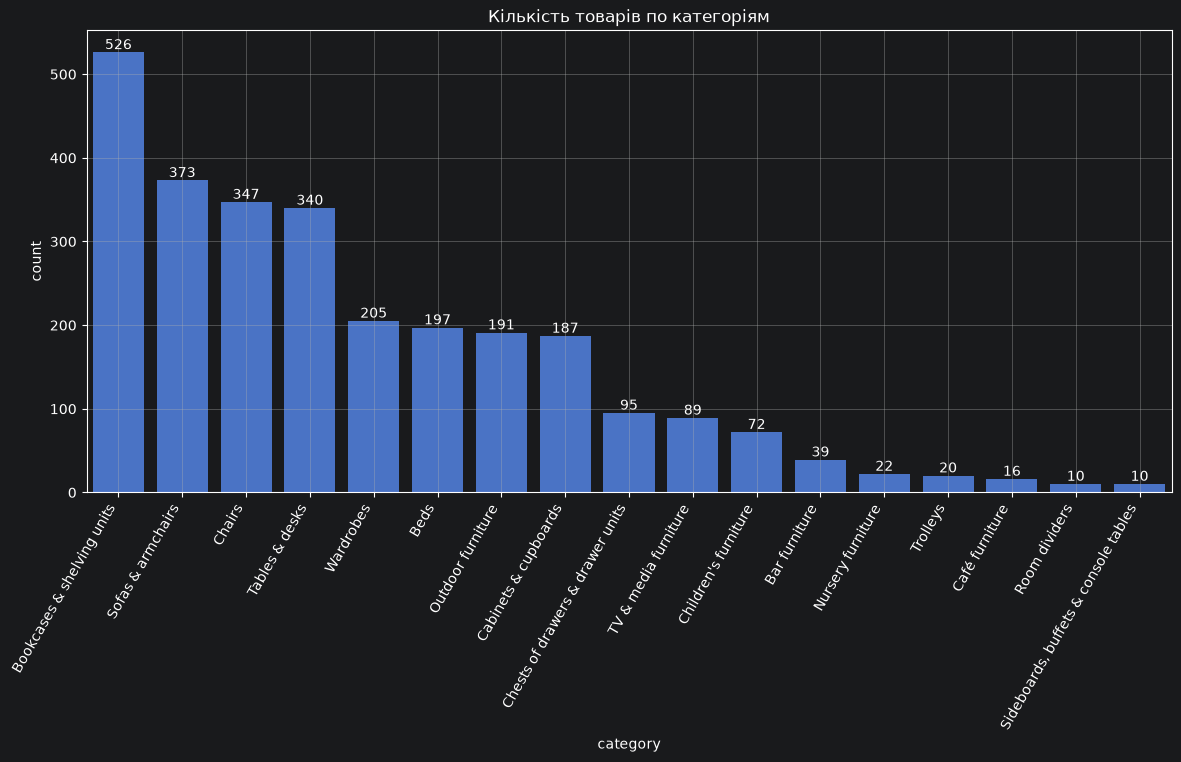

In [78]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    data=df_explode_categories,
    x="category",
    order=df_explode_categories["category"].value_counts().index
)

plt.xticks(rotation=60, ha="right")
plt.title("Кількість товарів по категоріям")

plt.grid()

add_bar_labels(ax)

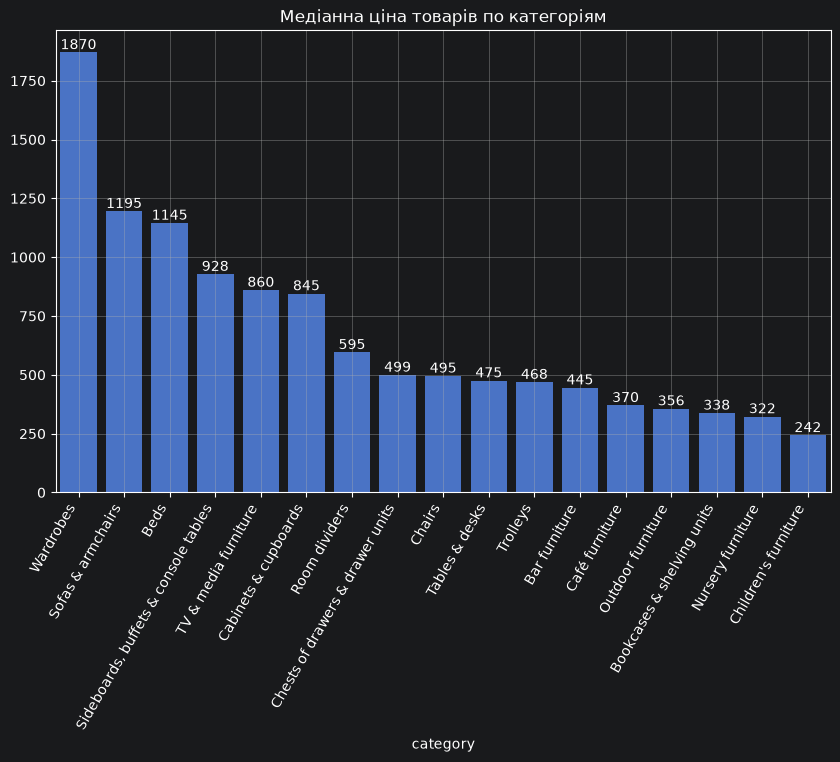

In [79]:
median_price = df_explode_categories.groupby("category")["price"].median().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=median_price.index, y=median_price.values)

plt.xticks(rotation=60, ha="right")
plt.title("Медіанна ціна товарів по категоріям")

plt.grid()

add_bar_labels(ax)

Найдорожчі категорії — шафи, дивани та ліжка, середній сегмент займають меблі для зберігання та медіа, а найдешевші — дитячі, вуличні та допоміжні меблі.

Text(0.5, 1.0, 'Кореляція ціни та розмірів')

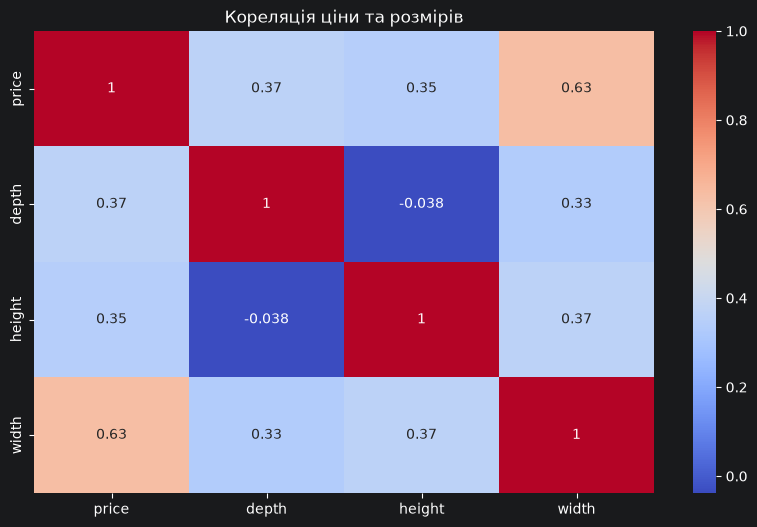

In [80]:
corr = df_unique[["price","depth","height","width"]].corr(method="spearman")

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm")

plt.title("Кореляція ціни та розмірів")

<Axes: >

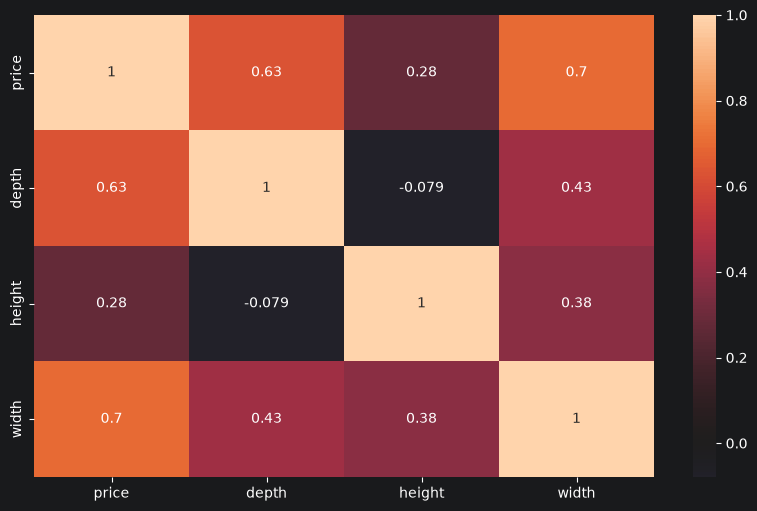

In [81]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df[["price", "depth", "height", "width"]].corr(),
    xticklabels= df[["price", "depth", "height", "width"]].corr().columns,
    yticklabels= df[["price", "depth", "height", "width"]].corr().columns,
    center= 0,
    annot= True
)

За теплокартами Пірсона та Спірмена можна зробити висновок, що:
1) більша ширина - більша ціна (price-width)
2) глибина та ширина пов"язані лінійно (price-depth) за Пірсоном
3) між глибиною та висотою зв"язку немає

Text(0.5, 1.0, 'Кількість товарів по дизайнерам (топ-15)')

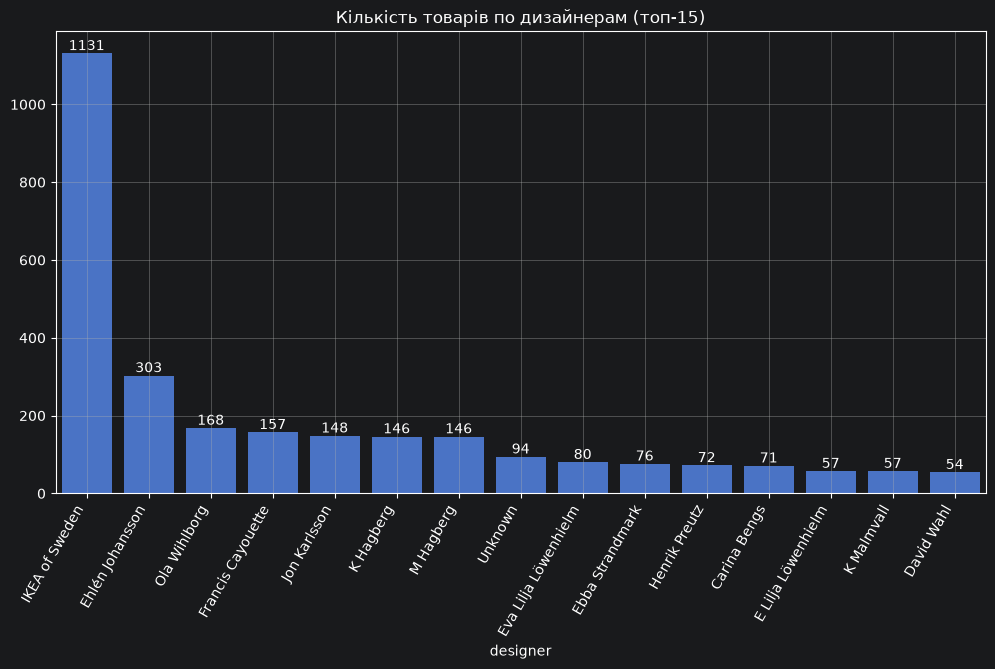

In [82]:
top_designers = df_explode_designer["designer"].value_counts().head(15)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=top_designers.index, y=top_designers.values)
plt.xticks(rotation=60, ha="right")
plt.grid()
add_bar_labels(ax)

plt.title("Кількість товарів по дизайнерам (топ-15)")

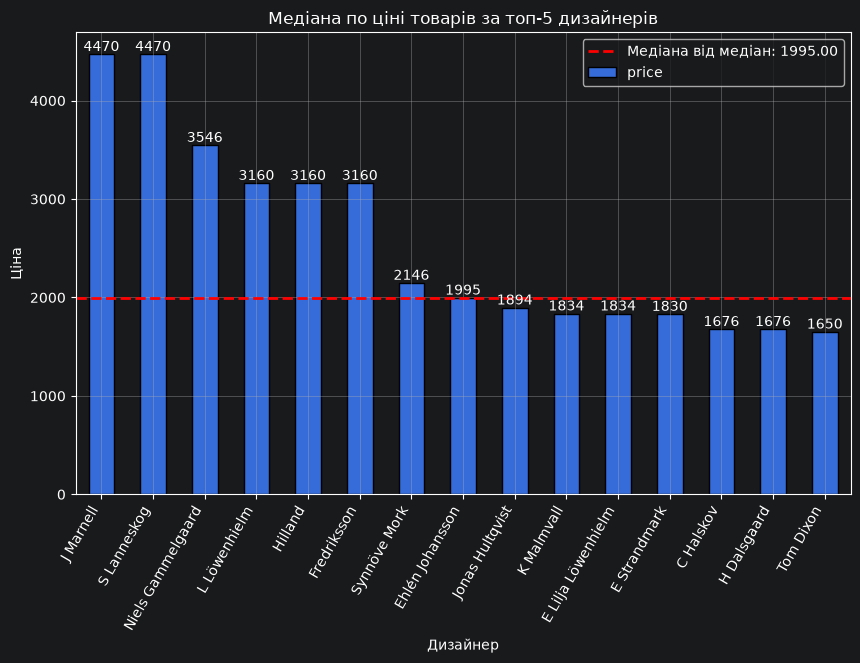

In [83]:
median_designer = df_explode_designer.groupby(["designer"])["price"].median().sort_values(ascending=False).head(15)

global_median_designers = median_designer.median()

plt.figure(figsize=(10,6))
ax = median_designer.plot(kind="bar", edgecolor="black")

plt.axhline(
    global_median_designers,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Медіана від медіан: {global_median_designers:.2f}"
)

plt.title("Медіана по ціні товарів за топ‑5 дизайнерів")
plt.ylabel("Ціна")
plt.xlabel("Дизайнер")
plt.xticks(rotation=60, ha="right")

plt.grid()
plt.legend()

add_bar_labels(ax)

Графік ілюструє, що ринок дизайнерських меблів поділений на два сегменти:
 - преміальні дизайнери з високими медіанними цінами,
 - масові дизайнери з більш доступними товарами.

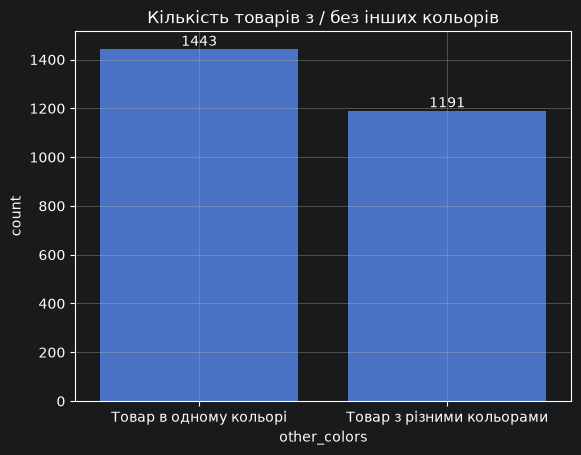

In [84]:
ax = sns.countplot(
    x=df_unique["other_colors"].map({
        True: "Товар з різними кольорами",
        False: "Товар в одному кольорі"
    }),
    order=["Товар в одному кольорі", "Товар з різними кольорами"]
)

plt.title("Кількість товарів з / без інших кольорів")

plt.grid()

add_bar_labels(ax)

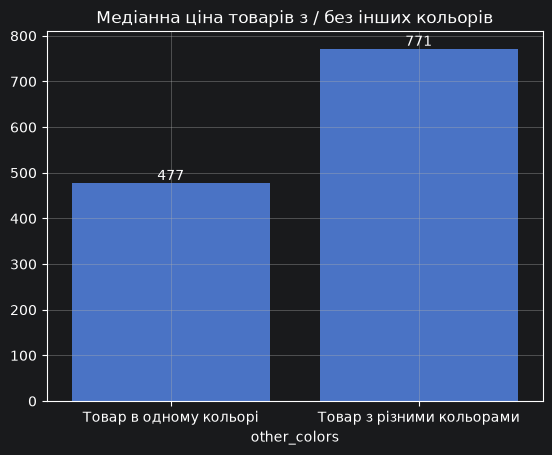

In [85]:
median_colors = df_unique.groupby(
    df_unique["other_colors"].map({
        True: "Товар з різними кольорами",
        False: "Товар в одному кольорі"
    })
)["price"].median()

ax = sns.barplot(
    x=median_colors.index,
    y=median_colors.values,
    order=["Товар в одному кольорі", "Товар з різними кольорами"]
)

plt.title("Медіанна ціна товарів з / без інших кольорів")

plt.grid()

add_bar_labels(ax)

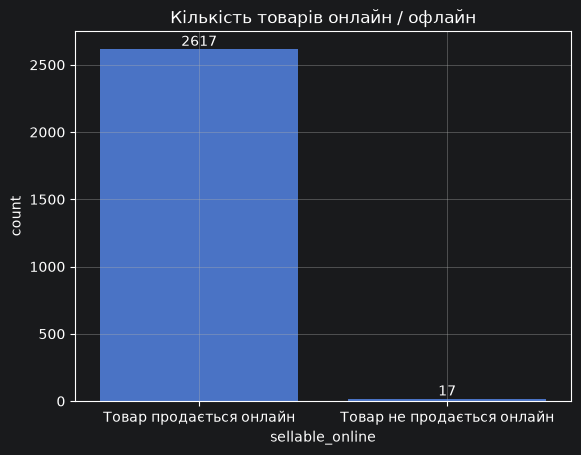

In [86]:
ax = sns.countplot(
    x=df_unique["sellable_online"].map({
        True: "Товар продається онлайн",
        False: "Товар не продається онлайн"
    }),
    order=["Товар продається онлайн", "Товар не продається онлайн"]
)

plt.title("Кількість товарів онлайн / офлайн")
plt.grid()
add_bar_labels(ax)

In [87]:
df_sell_offline = df_unique[df_unique["sellable_online"] == False]
df_sell_offline

,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size
465,20340824,EKEDALEN,Tables & desks,795.0,False,False,"Extendable table, 80/120x70 cm",Ehlén Johansson,48.0,75.0,70.0,795.0,1
472,29296874,EKEDALEN / EKEDALEN,Chairs,1245.0,False,False,"Table and 2 chairs, 80/120 cm",Ehlén Johansson,58.0,76.0,68.0,1245.0,1
482,69221283,EKEDALEN / ODGER,Chairs,1149.0,False,False,"Table and 2 chairs, 80/120 cm",Ehlén Johansson/J Löfgren/J Pettersson,58.0,76.0,68.0,1385.0,1
598,50468694,EMTEN,Sofas & armchairs,39.0,False,False,"Bath mat, 50x80 cm",IKEA of Sweden,98.0,83.0,50.0,39.0,1
826,50342478,HACKÅS,Bookcases & shelving units,50.0,False,False,"Handle, 300 mm",J Löfgren/J Pettersson,18.0,147.0,24.0,50.0,1
1731,80369112,NORDVIKEN,Bar furniture,275.0,False,False,"Bar stool with backrest, 75 cm",Francis Cayouette,47.0,101.0,40.0,275.0,1
1732,368814,NORDVIKEN,Bar furniture,995.0,False,False,"Bar table, 140x80 cm",Francis Cayouette,49.0,105.0,80.0,995.0,1
1738,9333523,NORDVIKEN / NORDVIKEN,Bar furniture,2095.0,False,False,Bar table and 4 bar stools,Francis Cayouette,49.0,102.0,48.0,2095.0,1
2129,50456417,SLÄKT,Beds,75.0,False,True,Headboard,Ebba Strandmark,89.0,40.0,90.0,75.0,1
2133,19326428,SLÄKT,Beds,520.0,False,False,"Ext bed frame with slatted bed base, ...",Ebba Strandmark/IKEA of Sweden,89.0,84.0,91.0,520.0,1


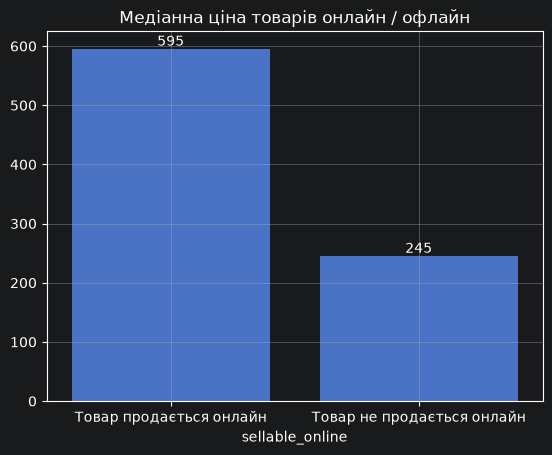

In [88]:
median_online = df_unique.groupby(
    df_unique["sellable_online"].map({
        True: "Товар продається онлайн",
        False: "Товар не продається онлайн"
    })
)["price"].median()

ax = sns.barplot(
    x=median_online.index,
    y=median_online.values,
    order=["Товар продається онлайн", "Товар не продається онлайн"]
)

plt.title("Медіанна ціна товарів онлайн / офлайн")
plt.grid()
add_bar_labels(ax)

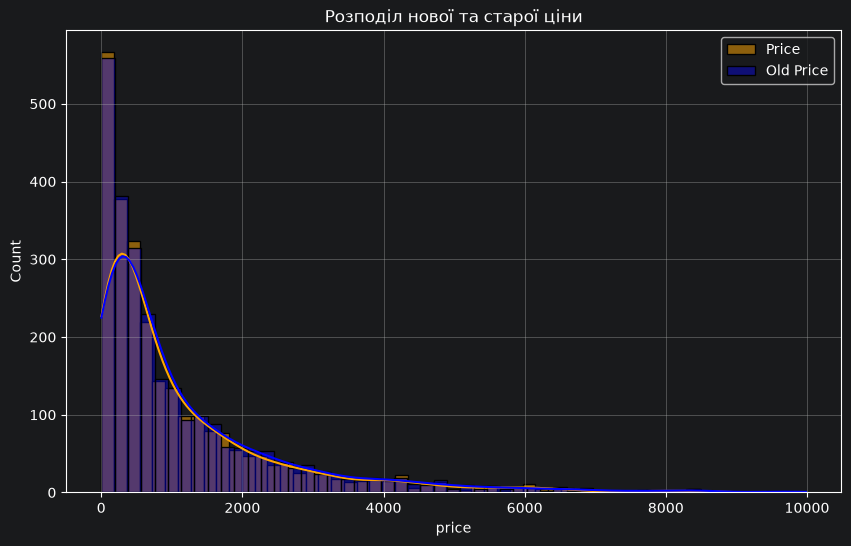

In [89]:
plt.figure(figsize=(10,6))
sns.histplot(df_unique["price"], kde=True, color="orange", label="Price")
sns.histplot(df_unique["old_price_num"], kde=True, color="blue", label="Old Price", alpha=0.4)
plt.legend()
plt.title("Розподіл нової та старої ціни")

plt.grid()

In [90]:
mean_old = df_unique["old_price_num"].mean()
mean_new = df_unique["price"].mean()

print("Середня стара ціна:", mean_old)
print("Середня нова ціна:", mean_new)

Середня стара ціна: 1179.9354593773728
Середня нова ціна: 1123.3225892179196


Гістограма показує, що структура розподілу змінилася. дешевих стало менше, середні ціни розтягнулись, але дорогі товари знизилися настільки, що середнє впало.


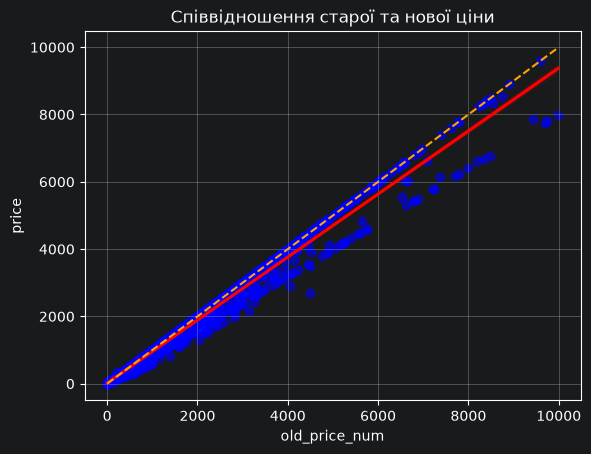

In [91]:
sns.regplot(
    data=df_unique,
    x="old_price_num",
    y="price",
    scatter_kws={"color": "blue", "alpha": 0.6, "label": "Товари"},
    line_kws={"color": "red", "label": "Лінія регресії"}
)
max_val = max(df_unique["old_price_num"].max(), df_unique["price"].max())
plt.plot([0, max_val], [0, max_val], color="orange", linestyle="--", label="y = x (стара = нова)")

plt.title("Співвідношення старої та нової ціни")
plt.grid()

In [92]:
trend = df_unique["price"] - df_unique["old_price_num"]

grown = (trend > 0).sum()
fallen = (trend < 0).sum()

print("Подорожчали:", grown)
print("Подешевшали:", fallen)

Подорожчали: 10
Подешевшали: 530


Лінія регресії (червона) показує загальну кореляцію, дешеві товари залишаються дешевими, дорогі — дорогими. Лінія у=х показує реальне порівняння: у більшості випадків стара ціна більша за нову.

Це стосується лише тих товарів, в яких була стара ціна.

Text(0.5, 1.0, 'Топ‑5 дизайнерів за кількістю товарів')

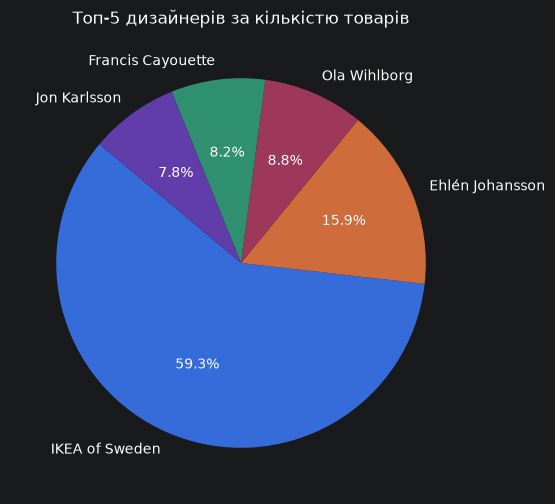

In [93]:
top5_designer = df_explode_designer["designer"].value_counts(). head(5)

plt.figure(figsize=(10, 6))
plt.pie(
    top5_designer.values,
    labels=top5_designer.index,
    autopct="%1.1f%%",
    startangle=140
)

plt.title("Топ‑5 дизайнерів за кількістю товарів")

Компанія має централізовану модель дизайну, де головний підрозділ IKEA of Sweden створює більшість товарів, а інші дизайнери додають унікальні лінійки. Баланс між виробництвом та дизайнерською різноманітністю.

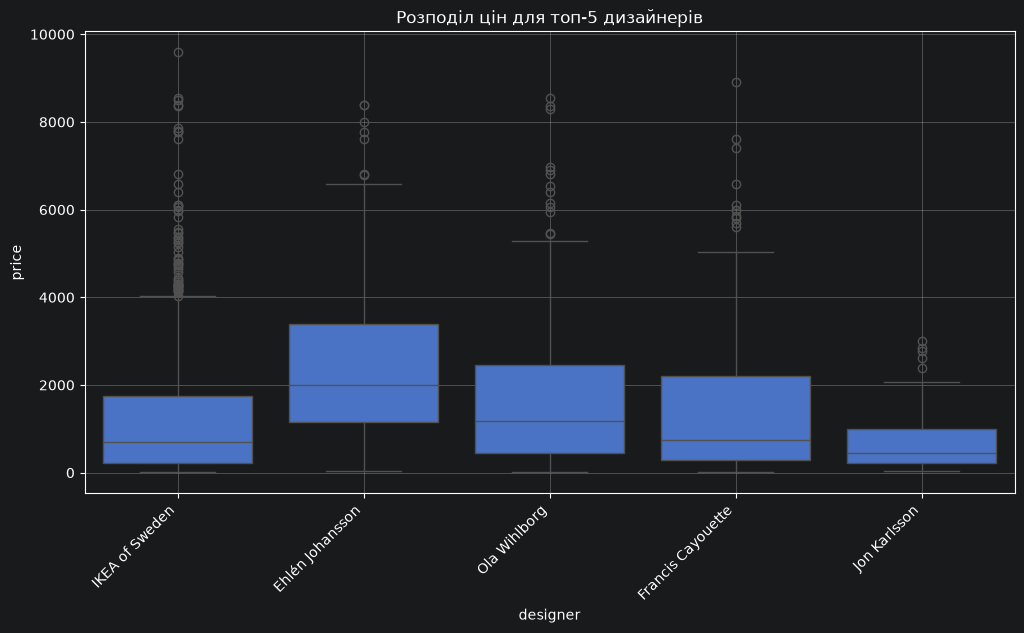

In [94]:
top_designers = df_explode_designer["designer"].value_counts().head(5)

plt.figure(figsize=(12,6))
sns.boxplot(
    x="designer",
    y="price",
    data=df_explode_designer[df_explode_designer["designer"].isin(top_designers.index)],
    order=top_designers.index
)
plt.title("Розподіл цін для топ‑5 дизайнерів")
plt.xticks(rotation=45, ha="right")

plt.grid()

Графік показує, що IKEA of Sweden охоплює весь спектр цін, тоді як інші дизайнери більш сфокусовані на конкретних сегментах.

In [95]:
df_explode_designer[df_explode_designer["designer"] == "J Marnell"].sort_values(by="price", ascending=True).head()

,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size
1651,50386245,MÖRBYLÅNGA,Tables & desks,2295.0,True,False,"Table, 140x85 cm",J Marnell,48.0,75.0,85.0,2295.0,1
1652,20293766,MÖRBYLÅNGA,Tables & desks,2495.0,True,False,"Table, 220x100 cm",J Marnell,48.0,74.0,100.0,2495.0,1
1658,19246097,MÖRBYLÅNGA / LEIFARNE,Chairs,3075.0,True,False,"Table and 4 chairs, 140x85 cm",J Marnell,58.0,76.0,68.0,3075.0,1
1660,19305044,MÖRBYLÅNGA / ODGER,Chairs,3475.0,True,False,"Table and 4 chairs, 140x85 cm",J Marnell,58.0,74.0,85.0,3475.0,1
1659,19131652,MÖRBYLÅNGA / LEIFARNE,Chairs,3665.0,True,False,"Table and 6 chairs, 220x100 cm",J Marnell,58.0,74.0,100.0,3665.0,1


Text(0.5, 1.0, 'Розподіл цін по категоріях')

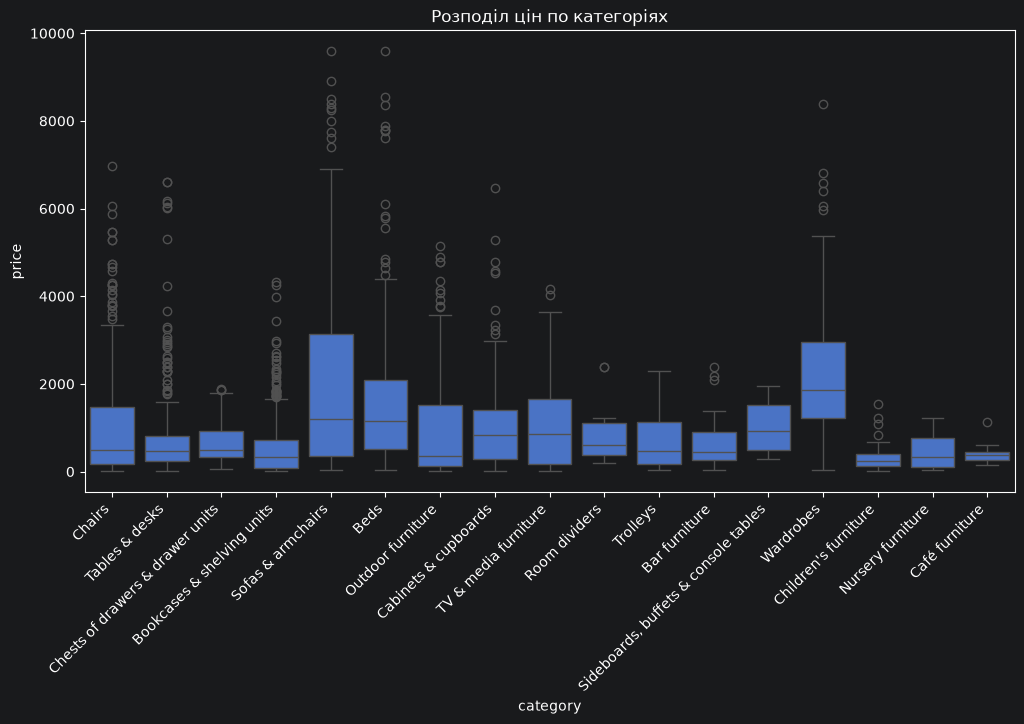

In [96]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_explode_categories, x="category", y="price")

plt.xticks(rotation=45, ha="right")
plt.title("Розподіл цін по категоріях")


У більшості видно широкий розкид, що означає різні рівні товарів — від бюджетних до преміальних.
Ціни залежать від функціональності та складності меблів: великі та багатофункціональні категорії (ліжка, шафи, дитячі меблі) мають широкий діапазон і високі медіани, тоді як простіші категорії (столи, стільці, полиці) залишаються більш доступними й стабільними за ціною.

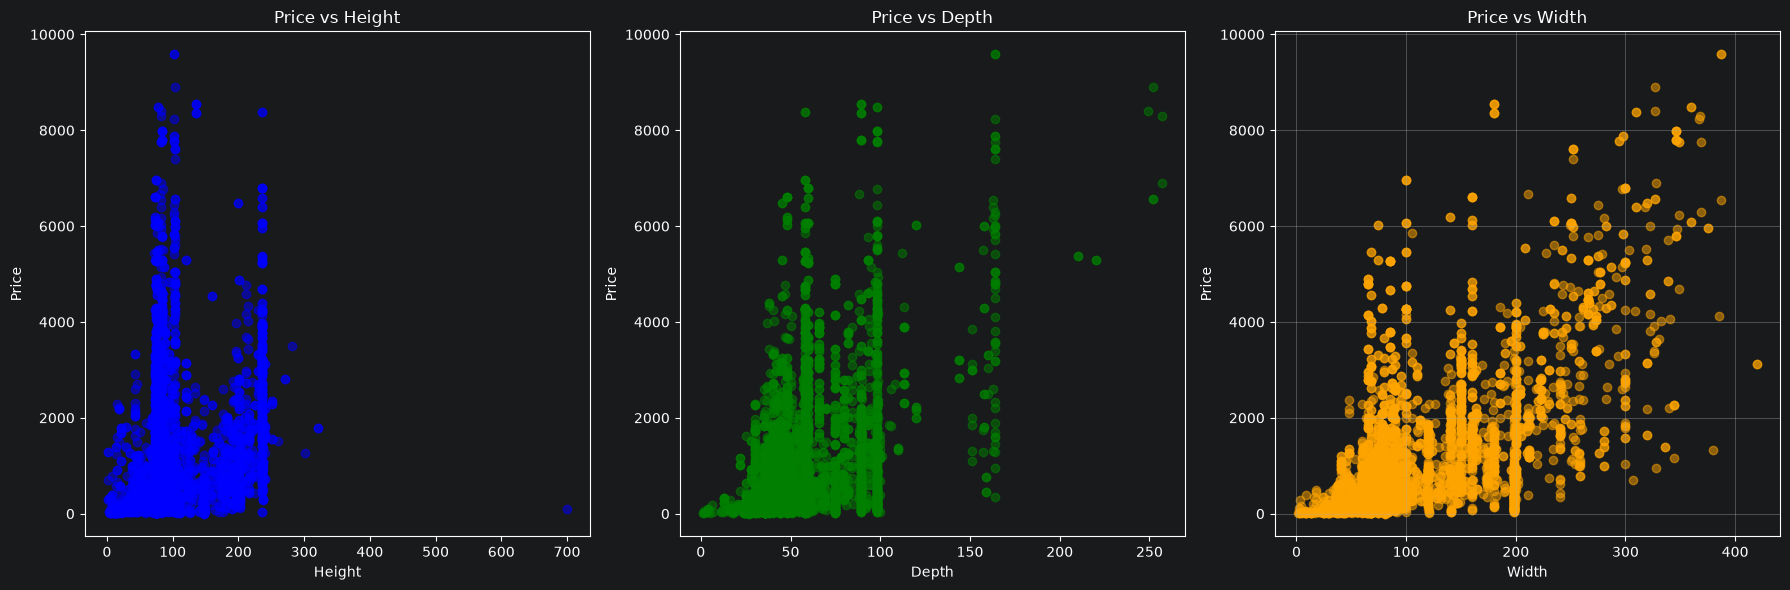

In [97]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))

# Ціна vs Height
axes[0].scatter(df_explode_designer["height"], df_explode_designer["price"], alpha=0.5, color="blue")
axes[0].set_xlabel("Height")
axes[0].set_ylabel("Price")
axes[0].set_title("Price vs Height")

# Ціна vs Depth
axes[1].scatter(df_explode_designer["depth"], df_explode_designer["price"], alpha=0.5, color="green")
axes[1].set_xlabel("Depth")
axes[1].set_ylabel("Price")
axes[1].set_title("Price vs Depth")

# Ціна vs Width
axes[2].scatter(df_explode_designer["width"], df_explode_designer["price"], alpha=0.5, color="orange")
axes[2].set_xlabel("Width")
axes[2].set_ylabel("Price")
axes[2].set_title("Price vs Width")

plt.tight_layout()

plt.grid()

Фізичні розміри меблів (висота, ширина, глибина) не є головним фактором ціноутворення.

Scatter‑графіки підтверджують, що розмір лише частково впливає на вартість.

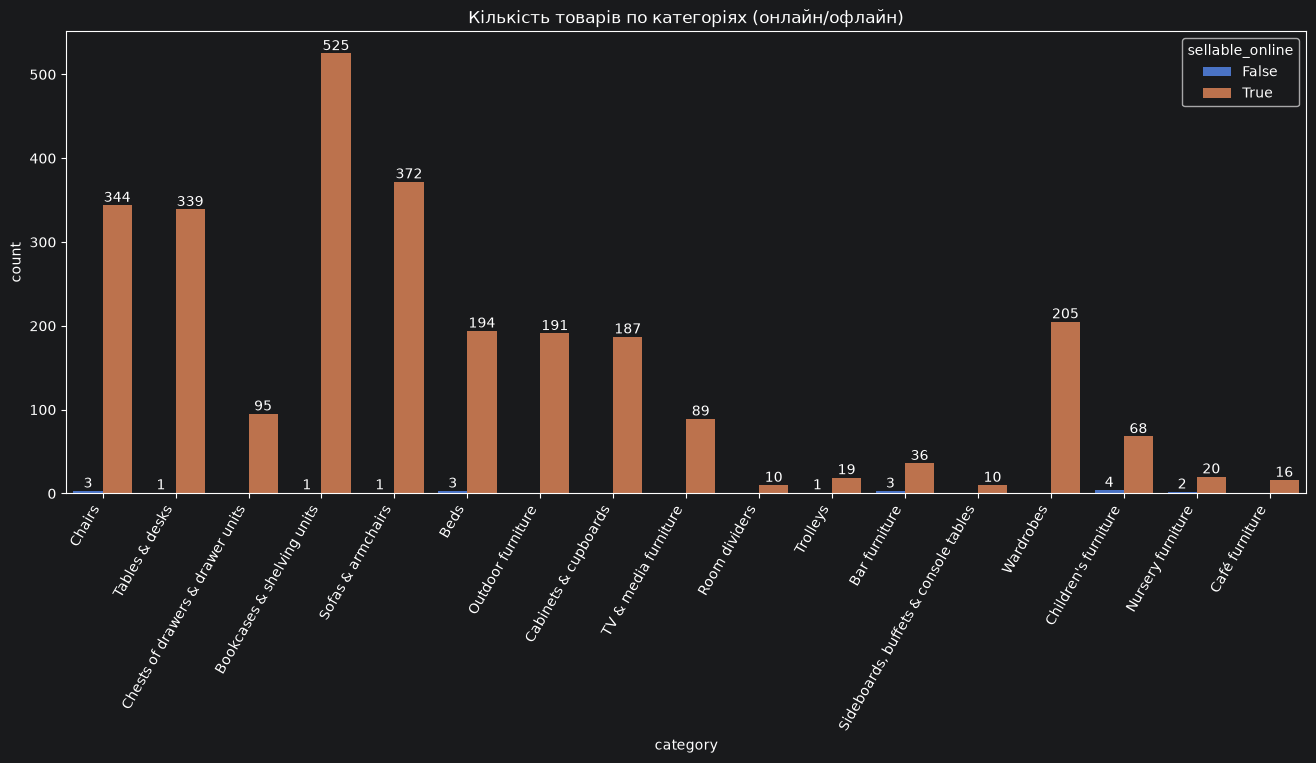

In [98]:
plt.figure(figsize=(16,6))
ax = sns.countplot(x="category", hue="sellable_online", data=df_explode_categories)
plt.xticks(rotation=60, ha="right")
plt.title("Кількість товарів по категоріях (онлайн/офлайн)")

add_bar_labels(ax)

Компанія робить ставку на онлайн‑продажі як основний канал, залишаючи офлайн лише для окремих позицій.

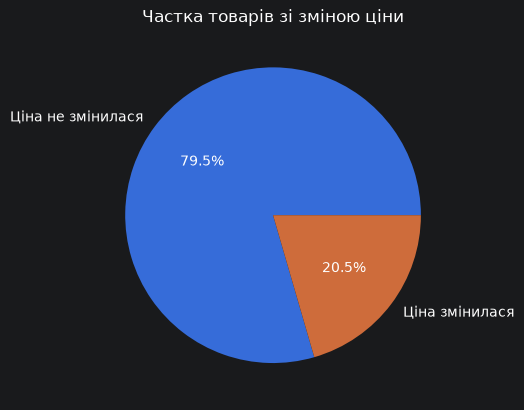

In [99]:
labels_map = {0: "Ціна не змінилася", 1: "Ціна змінилася"}

price_changed = (df_unique["old_price_num"] != df_unique["price"]).astype(int)

counts = price_changed.value_counts()
counts.index = counts.index.map(labels_map)

counts.plot(kind="pie", autopct="%1.1f%%")
plt.title("Частка товарів зі зміною ціни")

plt.grid()

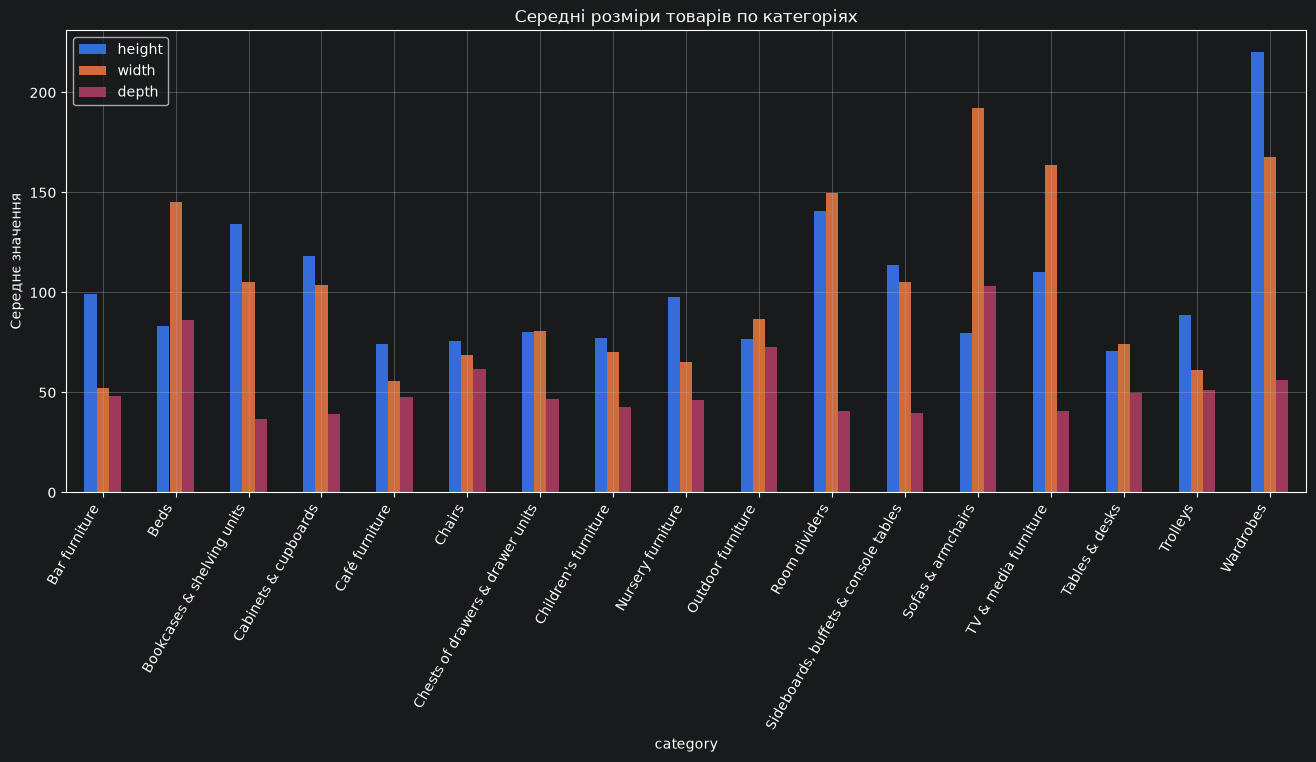

In [100]:
df_explode_categories.groupby("category")[["height","width","depth"]].mean().plot(kind="bar", figsize=(16,6))
plt.title("Середні розміри товарів по категоріях")
plt.ylabel("Середнє значення")
plt.xticks(rotation=60, ha="right")

plt.grid()

Графік показує чітку залежність: чим функціональніша категорія для зберігання або основного використання (шафи, ліжка, дивани), тим більші її середні розміри.

In [101]:
df_explode_designer

,item_id,name,category,price,sellable_online,other_colors,short_description,designer,depth,height,width,old_price_num,pack_size
0,10219178,ADDE,Chairs,40.0,True,True,Chair,Marcus Arvonen,47.0,77.0,39.0,40.0,1
1,90217972,ADILS,Tables & desks,15.0,True,True,Leg,Unknown,48.0,70.0,74.0,15.0,1
2,70253541,AGAM,Chairs,195.0,True,False,Junior chair,IKEA of Sweden,43.0,79.0,41.0,195.0,1
3,50058376,AGEN,Chairs,245.0,True,False,Chair,Unknown,56.0,79.0,58.0,245.0,1
4,40419982,ALEFJÄLL,Chairs,1295.0,True,True,Office chair,Unknown,64.0,76.0,64.0,1295.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2633,79161575,ÖVRARYD / JANINGE,Chairs,1535.0,True,False,"Table and 4 chairs, 150 cm",David Wahl,58.0,76.0,78.0,1645.0,1
2633,79161575,ÖVRARYD / JANINGE,Chairs,1535.0,True,False,"Table and 4 chairs, 150 cm",John,58.0,76.0,78.0,1645.0,1
2633,79161575,ÖVRARYD / JANINGE,Chairs,1535.0,True,False,"Table and 4 chairs, 150 cm",Jonas,58.0,76.0,78.0,1645.0,1
2633,79161575,ÖVRARYD / JANINGE,Chairs,1535.0,True,False,"Table and 4 chairs, 150 cm",Paul,58.0,76.0,78.0,1645.0,1


(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5]),
 [Text(0.5, 0, 'Carina Bengs'),
  Text(1.5, 0, 'E Lilja Löwenhielm'),
  Text(2.5, 0, 'Ebba Strandmark'),
  Text(3.5, 0, 'Ehlén Johansson'),
  Text(4.5, 0, 'Eva Lilja Löwenhielm'),
  Text(5.5, 0, 'Francis Cayouette'),
  Text(6.5, 0, 'Henrik Preutz'),
  Text(7.5, 0, 'IKEA of Sweden'),
  Text(8.5, 0, 'Jon Karlsson'),
  Text(9.5, 0, 'K Hagberg'),
  Text(10.5, 0, 'K Malmvall'),
  Text(11.5, 0, 'M Hagberg'),
  Text(12.5, 0, 'Marcus Arvonen'),
  Text(13.5, 0, 'Ola Wihlborg'),
  Text(14.5, 0, 'Unknown')])

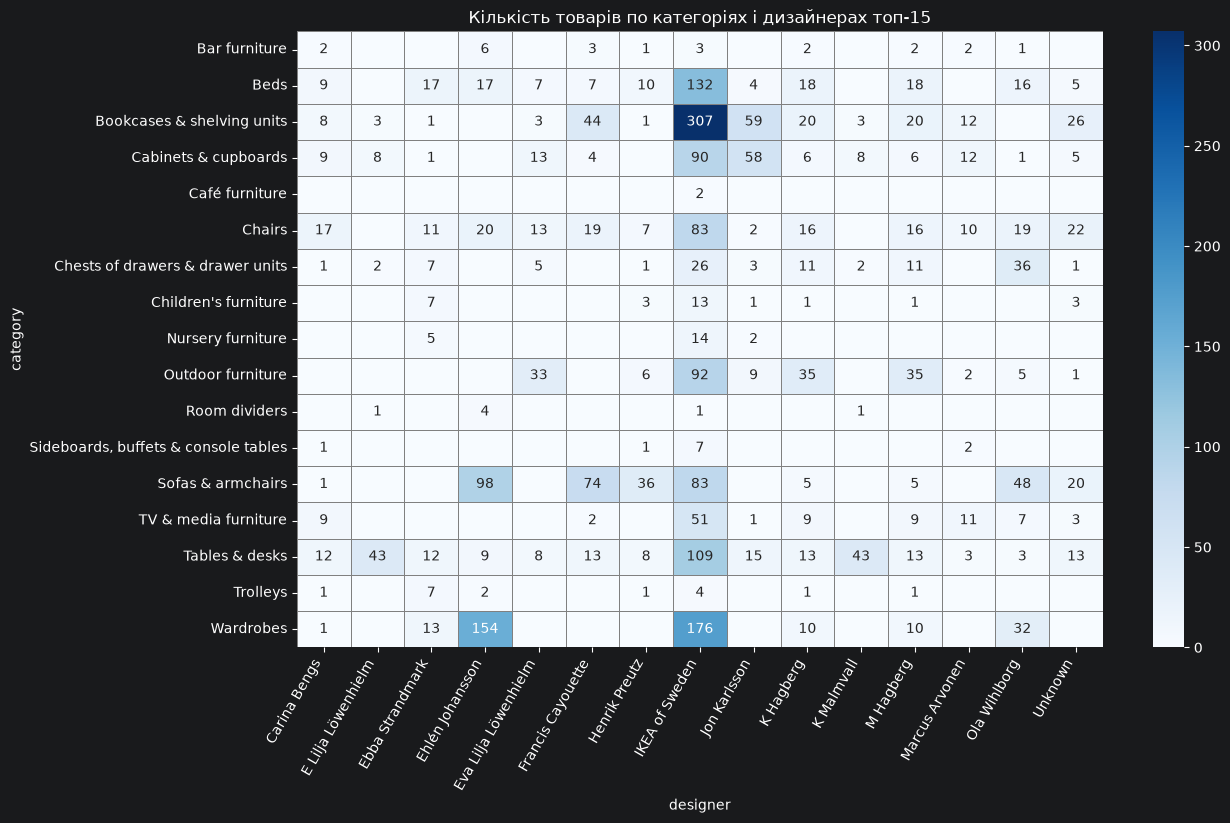

In [102]:
df_categories_designers = df_explode_categories[["item_id", "category"]].merge(
    df_explode_designer[["item_id", "designer"]],
    on="item_id",
    how="inner"
)

top_designers = df_categories_designers["designer"].value_counts().head(15).index
df_top = df_categories_designers[df_categories_designers["designer"].isin(top_designers)]

pivot = df_top.pivot_table(
    index="category",
    columns="designer",
    values="item_id",
    aggfunc="count"
).fillna(0)

annot_data = np.where(pivot>0, pivot.astype(int).astype(str), "")

plt.figure(figsize=(13,8))
sns.heatmap(
    pivot,
    cmap="Blues",
    cbar=True,
    annot=annot_data,
    fmt="",
    linewidths=0.5,
    linecolor="gray"
)
plt.title("Кількість товарів по категоріях і дизайнерах топ-15")
plt.xticks(rotation=60, ha="right")

In [103]:
df_explode_categories["category"].unique()

<StringArray>
[                              'Chairs',
                       'Tables & desks',
     'Chests of drawers & drawer units',
           'Bookcases & shelving units',
                    'Sofas & armchairs',
                                 'Beds',
                    'Outdoor furniture',
                 'Cabinets & cupboards',
                 'TV & media furniture',
                        'Room dividers',
                             'Trolleys',
                        'Bar furniture',
 'Sideboards, buffets & console tables',
                            'Wardrobes',
                 'Children's furniture',
                    'Nursery furniture',
                       'Café furniture']
Length: 17, dtype: str

На цьому графіку видно, що окремі дизайнери концентруються на конкретних категоріях. Наприклад, "Ehlen Johansson" має найбільший внесок у "Sofas & armchairs" та "Wardrobes", у то час як "IKEA of Sweden" більше сфокусовані на "Beds", "Bookcases & shelving units", "Tables & desks" та "Wardrobes".
Інші дизайнери займають нішеві позиції.

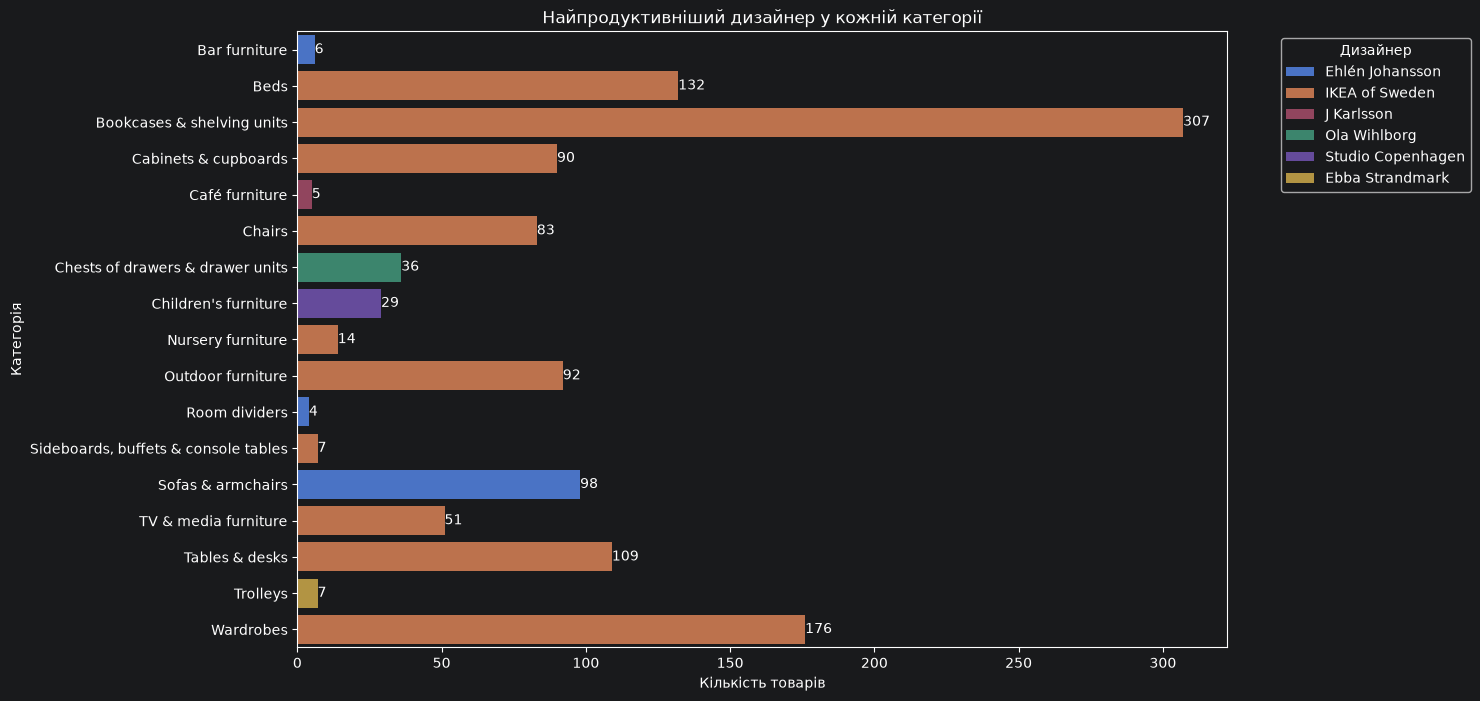

In [104]:
top_designer_per_category = (
    df_categories_designers.groupby(["category","designer"])["item_id"]
    .count()
    .reset_index()
    .sort_values(["category","item_id"], ascending=[True,False])
    .groupby("category")
    .first()
    .reset_index()
)

plt.figure(figsize=(12,8))
ax = sns.barplot(
    data=top_designer_per_category,
    y="category",
    x="item_id",
    hue="designer",
    dodge=False
)

plt.xlabel("Кількість товарів")
plt.ylabel("Категорія")
plt.title("Найпродуктивніший дизайнер у кожній категорії")
plt.legend(title="Дизайнер", bbox_to_anchor=(1.05, 1), loc="upper left")

add_bar_labels(ax)

У більшості категорій найбільше товарів створено IKEA of Sweden. Особливо це видно в «Bookcases & shelving units» (307 товарів) та «Wardrobes» (176 товарів) - що підтверджує і heatmap вище.

Ehlén Johansson та Ola Wihlborg з’являються в окремих категоріях, але їх внесок значно менший.

Studio Copenhagen та Ebba Strandmark теж представлені, проте не домінують.

«Bar furniture», «Café furniture», «Room dividers», «Sideboards, buffets & console tables», «Trolleys» мають дуже мало товарів (менше 10). Це може означати вузьку спеціалізацію або низький попит.

# Перша гіпотеза: площа меблів (width × depth) впливає на ціну.
Нульова гіпотеза - площа меблів не впливає на ціну.

Альтернативна гіпотеза - більша площа меблів асоціюється з вищою ціною.

In [105]:
df_unique["area"] = df_unique["width"] * df_unique["depth"]
df_unique["price_ln"] = np.log(df_unique["price"])

small = df_unique[df_unique["area"] < df_unique["area"].median()]["price_ln"]
large = df_unique[df_unique["area"] >= df_unique["area"].median()]["price_ln"]

<Axes: xlabel='price_ln', ylabel='Count'>

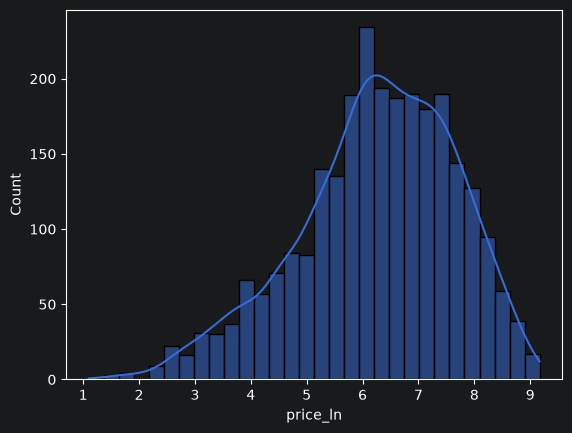

In [106]:
sns.histplot(df_unique["price_ln"], kde=True)

In [107]:
# 1) Pearson correlation
pearson_corr, pearson_p = pearsonr(df_unique["area"], df_unique["price_ln"])
print(f"Pearson correlation: {pearson_corr}, \np-value: {pearson_p}")

Pearson correlation: 0.4861553527701834, 
p-value: 2.4868370446449075e-156


Pearson correlation: 0,52 - це помітний позитивний зв’язок: коли площа меблів збільшується, ціна теж зростає.

p‑value дуже маленьке (< 0.001) результат надійний, випадковість виключена.

Нульова гіпотеза відкидається, альтернативна підтверджується.

In [108]:
# 2) Spearman correlation
spearman_corr, spearman_p = spearmanr(df_unique["area"], df_unique["price_ln"])
print(f"Spearman correlation: {spearman_corr}, \np-value: {spearman_p}")

Spearman correlation: 0.6492730446035305, 
p-value: 0.0


Spearman correlation: 0,72 - це сильний позитивний зв’язок: коли площа меблів збільшується, ціна теж зростає.

p‑value 0,0 результат абсолютно надійний, випадковість виключена.

Нульова гіпотеза відкидається, альтернативна підтверджується.

In [109]:
# 3) Mann-Whitney U test
statistic_uw, p_value_uw = mannwhitneyu(small, large)
print(f"Mann-Whitney U statistic: {statistic_uw}, \np-value: {p_value_uw}")

Mann-Whitney U statistic: 296974.0, 
p-value: 1.03427904496484e-187


p‑value 4.17e‑162 (<0.05) надзвичайно маленьке значення: різниця між групами не випадкова, а реальна.

У групі меблів з великою площею ціни значно відрізняються від групи з малою площею.
Тобто площа меблів має статистично значущий вплив на ціну.



In [110]:
# 4) ANOVA
df_unique["area_group"] = pd.qcut(df_unique["area"], q=3, labels=["small","medium","large"])
groups = [df_unique[df_unique["area_group"]==g]["price_ln"] for g in df_unique["area_group"].unique()]
statistic_anova, p_value_anova = f_oneway(*groups)
print(f"ANOVA statistic:, {statistic_anova}, \np-value: {p_value_anova}")

ANOVA statistic:, 735.4919777319768, 
p-value: 1.885492398876372e-254


Статистика 849.4 - показник різниці між групами.

p‑value = 2.49e‑285 надзвичайно маленьке: різниця між групами точно не випадкова.

F дуже велике, p‑value маленьке - хоча б одна група суттєво відрізняється від інших.

Нульову гіпотезу відкидаємо.
Ціни меблів змінюються залежно від площі: від малих до великих груп є значуща різниця.

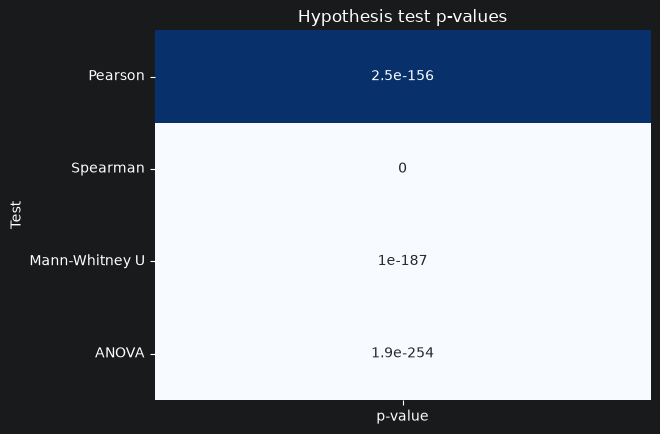

In [111]:
results = pd.DataFrame({
    "Test": ["Pearson", "Spearman", "Mann-Whitney U", "ANOVA"],
    "p-value": [pearson_p, spearman_p, p_value_uw, p_value_anova]
})

sns.heatmap(results.set_index("Test"), annot=True, cmap="Blues", cbar=False)
plt.title("Hypothesis test p-values")
plt.show()

### Усі три тести одностайно підтвердили гіпотезу: площа меблів має значущий і позитивний вплив на ціну. Чим більша площа, тим дорожче меблі, і це не випадковість, а статистично доведений факт.

# Друга гіпотеза: Дизайнер меблів впливає на ціну.
Нульова гіпотеза - ціни не залежать від дизайнера.

Альтернативна гіпотеза - меблі від різних дизайнерів мають різні ціни.

In [112]:
df_explode_designer = df_explode_designer.merge(
    df_unique[["item_id", "price_ln"]],
    on="item_id",
    how="left"
)

In [113]:
group_sizes = df_explode_designer["designer"].value_counts()
print(group_sizes.head(20))

designer
IKEA of Sweden          1131
Ehlén Johansson          303
Ola Wihlborg             168
Francis Cayouette        157
Jon Karlsson             148
K Hagberg                146
M Hagberg                146
Unknown                   94
Eva Lilja Löwenhielm      80
Ebba Strandmark           76
Henrik Preutz             72
Carina Bengs              71
E Lilja Löwenhielm        57
K Malmvall                57
David Wahl                54
Gillis Lundgren           46
Marcus Arvonen            45
Tord Björklund            44
Nike Karlsson             43
A Fredriksson             29
Name: count, dtype: int64


In [114]:
unique_prices_per_designer = df_explode_designer.groupby("designer")["price_ln"].nunique()
print(unique_prices_per_designer.sort_values().head(20))

designer
A Huldén              1
C Styrbjörn           1
Charlie Styrbjörn     1
E Thomasson           1
Eva Schildt           1
Lars Norinder         1
Jooyeon Lee           1
Johanna Jelinek       1
Magnus Elebäck        1
M Axelsson            1
S Dahlman             1
Malin Unnborn         1
Lycke von Schantz     1
Lisel Garsveden       1
H Brogård             2
Elizabet Gutierrez    2
P Süssmann            2
Niels Gammelgaard     2
Anna Palleschitz      2
Annie Huldén          2
Name: price_ln, dtype: int64


In [115]:
# 1) Kruskal-Wallis test
groups = [df_explode_designer[df_explode_designer["designer"]==d]["price_ln"]
          for d in df_explode_designer["designer"].unique()]

statistic_kw, p_value_kw = kruskal(*groups)
print(f"Kruskal-Wallis statistic: {statistic_kw}, \np-value: {p_value_kw}")

Kruskal-Wallis statistic: 813.5957056834051, 
p-value: 3.1378490179491598e-108


p‑value надзвичайно маленьке: різниця між групами точно не випадкова. Тобто нульова гіпотеза відкидається.

In [116]:
# ANOVA (One-way)
from scipy.stats import f_oneway

groups = [df_explode_designer[df_explode_designer["designer"]==d]["price_ln"]
          for d in df_explode_designer["designer"].unique()]

statistic_anova_2, p_value_anova_2 = f_oneway(*groups)
print(f"ANOVA statistic: {statistic_anova_2}, \np-value: {p_value_anova_2}")

ANOVA statistic: 9.190459363923496, 
p-value: 2.0021929555430214e-124


p‑value надзвичайно маленьке: середні ціни меблів статистично значуще відрізняються між різними дизайнерами. Тобто нульова гіпотеза відкидається.

In [117]:
# Chi-square test
import pandas as pd
from scipy.stats import chi2_contingency

df_explode_designer["price_group"] = pd.qcut(df_explode_designer["price_ln"], q=3, labels=["low","medium","high"])

contingency_table = pd.crosstab(df_explode_designer["designer"], df_explode_designer["price_group"])

chi2, p_value_cs, dof, expected = chi2_contingency(contingency_table)
print(f"Chi-square statistic: {chi2}, \np-value: {p_value_cs}")

Chi-square statistic: 964.2368370807159, 
p-value: 2.4375121541802913e-94


p‑value надзвичайно маленьке: існує статистично значущий зв’язок між дизайнером і ціновою групою меблів. Тобто нульова гіпотеза відкидається.

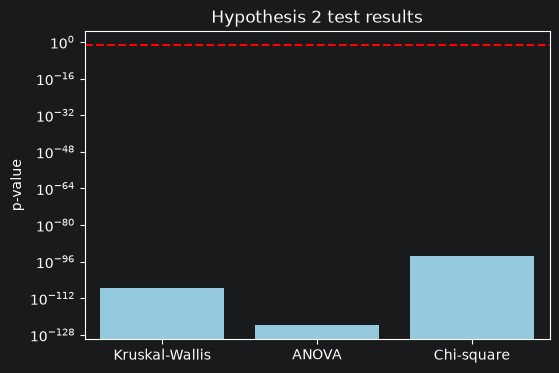

In [118]:
tests = ["Kruskal-Wallis", "ANOVA", "Chi-square"]
p_values = [p_value_kw, p_value_anova_2, p_value_cs]  # збережи їх у змінні при обчисленні

plt.figure(figsize=(6,4))
sns.barplot(x=tests, y=p_values, color="skyblue")
plt.axhline(0.05, color="red", linestyle="--")
plt.ylabel("p-value")
plt.title("Hypothesis 2 test results")
plt.yscale("log")   # щоб було видно дуже маленькі значення
plt.show()


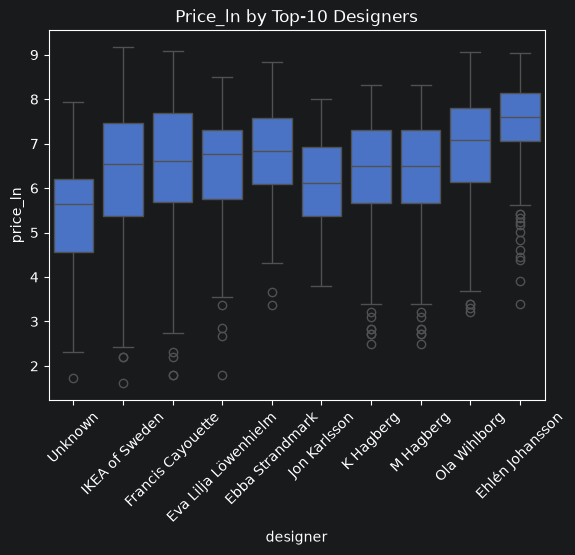

In [119]:
top_designers = df_explode_designer["designer"].value_counts().head(10).index
sns.boxplot(x="designer", y="price_ln", data=df_explode_designer[df_explode_designer["designer"].isin(top_designers)])
plt.xticks(rotation=45)
plt.title("Price_ln by Top-10 Designers")
plt.show()


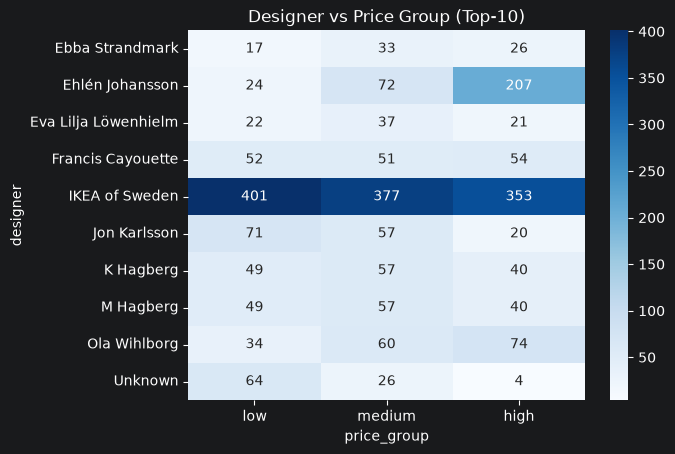

In [120]:
top_designers = df_explode_designer["designer"].value_counts().head(10).index
contingency_table_top = pd.crosstab(
    df_explode_designer[df_explode_designer["designer"].isin(top_designers)]["designer"],
    df_explode_designer["price_group"]
)
sns.heatmap(contingency_table_top, annot=True, fmt="d", cmap="Blues")
plt.title("Designer vs Price Group (Top-10)")
plt.show()


### Усі три тести показали надзвичайно низькі p‑value, що значно менше порогового рівня 0.05. Це дозволяє впевнено відкинути нульову гіпотезу. Таким чином, дизайнер має статистично значущий вплив на ціну меблів: різні дизайнери асоціюються з різними рівнями вартості, і ця різниця не є випадковою.

In [121]:
df_unique["n_categories"] = df_unique["category"].str.split("/").apply(len)
df_unique["n_designers"] = df_unique["designer"].str.split("/").apply(len)
df_check = df_unique[(df_unique["n_categories"] > 1) & (df_unique["n_designers"] > 1)]
df_check[["item_id", "name", "category", "designer", "n_categories", "n_designers"]].head(20)

,item_id,name,category,designer,n_categories,n_designers
73,30338415,BAGGANÄS,Bookcases & shelving units/Cabinets & cupboard...,A Fredriksson/H Preutz,3,2
74,338412,BAGGANÄS,Bookcases & shelving units/Cabinets & cupboards,A Fredriksson/H Preutz,2,2
75,10338421,BAGGANÄS,Bookcases & shelving units/Cabinets & cupboard...,A Fredriksson/H Preutz,3,2
76,338407,BAGGANÄS,Bookcases & shelving units/TV & media furniture,A Fredriksson/H Preutz,2,2
77,20338411,BAGGANÄS,Bookcases & shelving units/TV & media furniture,A Fredriksson/H Preutz,2,2
99,89286513,BEKANT,Cabinets & cupboards/Chests of drawers & drawe...,Eva Lilja Löwenhielm/IKEA of Sweden,2,2
101,69286806,BEKANT,Cabinets & cupboards/Tables & desks,Eva Lilja Löwenhielm/IKEA of Sweden,2,2
150,80322855,BERGHALLA,Bookcases & shelving units/TV & media furniture,A Fredriksson/H Preutz,2,2
191,29300852,BESTÅ,"Cabinets & cupboards/Sideboards, buffets & con...",IKEA of Sweden/Marcus Arvonen,2,2
196,59301483,BESTÅ,Cabinets & cupboards/TV & media furniture,Carl Öjerstam/IKEA of Sweden/Marcus Arvonen,2,3


In [122]:
df_model = df_unique.copy()

In [123]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 2634 entries, 0 to 2633
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   item_id            2634 non-null   int64   
 1   name               2634 non-null   str     
 2   category           2634 non-null   str     
 3   price              2634 non-null   float64 
 4   sellable_online    2634 non-null   bool    
 5   other_colors       2634 non-null   bool    
 6   short_description  2634 non-null   str     
 7   designer           2634 non-null   str     
 8   depth              2634 non-null   float64 
 9   height             2634 non-null   float64 
 10  width              2634 non-null   float64 
 11  old_price_num      2634 non-null   float64 
 12  pack_size          2634 non-null   int64   
 13  area               2634 non-null   float64 
 14  price_ln           2634 non-null   float64 
 15  area_group         2634 non-null   category
 16  n_categories     

# Третя гіпотеза: Наявність інших кольорів у товару впливає на ціну.
Нульова гіпотеза - наявність інших кольорів (other_colors) не впливає ціни товару.

Альтернативна гіпотеза - наявність інших кольорів (other_colors) впливає ціни товару

In [124]:
group1 = df_model[df_model["other_colors"] == True]["price_ln"]
group2 = df_model[df_model["other_colors"] == False]["price_ln"]
stat, p_value = mannwhitneyu(group1, group2, alternative="two-sided")
print(f"Mann-Whitney U: {stat}, \np-value: {p_value}")

Mann-Whitney U: 1004637.0, 
p-value: 7.361921955256552e-14


p‑value < 0.05 - наявність інших кольорів у товарів дійсно впливають на ціну.

In [125]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 2634 entries, 0 to 2633
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   item_id            2634 non-null   int64   
 1   name               2634 non-null   str     
 2   category           2634 non-null   str     
 3   price              2634 non-null   float64 
 4   sellable_online    2634 non-null   bool    
 5   other_colors       2634 non-null   bool    
 6   short_description  2634 non-null   str     
 7   designer           2634 non-null   str     
 8   depth              2634 non-null   float64 
 9   height             2634 non-null   float64 
 10  width              2634 non-null   float64 
 11  old_price_num      2634 non-null   float64 
 12  pack_size          2634 non-null   int64   
 13  area               2634 non-null   float64 
 14  price_ln           2634 non-null   float64 
 15  area_group         2634 non-null   category
 16  n_categories     

In [126]:
drop_cols = [
                "item_id",
                "name",
                "sellable_online",
                "price_ln",
                "short_description",
                "old_price_num", "pack_size",
                "area", "area_group"
]

df_model = df_model.drop(columns=drop_cols, errors="ignore")

In [127]:
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 2634 entries, 0 to 2633
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   category      2634 non-null   str    
 1   price         2634 non-null   float64
 2   other_colors  2634 non-null   bool   
 3   designer      2634 non-null   str    
 4   depth         2634 non-null   float64
 5   height        2634 non-null   float64
 6   width         2634 non-null   float64
 7   n_categories  2634 non-null   int64  
 8   n_designers   2634 non-null   int64  
dtypes: bool(1), float64(4), int64(2), str(2)
memory usage: 167.3 KB


In [128]:
df_model.shape

(2634, 9)

In [129]:
category_medians = df_explode_categories.groupby("category")["price"].median().to_dict()
designer_medians = df_explode_designer.groupby("designer")["price"].median().to_dict()

global_median = df_model["price"].median()

In [130]:
def transform(df):
    df = df.copy()
    df["category_median_price"] = df["category"].apply(
        lambda cats: np.median([category_medians[c.strip()] for c in cats.split("/") if c.strip() in category_medians])
    )
    df["designer_median_price"] = df["designer"].apply(
        lambda ds: np.median([designer_medians[d.strip()] for d in ds.split("/") if d.strip() in designer_medians])
    )

    return df[[
        "designer_median_price",
        "category_median_price",
        "width", "height", "depth",
        "other_colors",
        "n_designers"
    ]]

In [131]:
df_transformed = transform(df_model)

In [132]:
df_transformed.isna().sum()

designer_median_price    0
category_median_price    0
width                    0
height                   0
depth                    0
other_colors             0
n_designers              0
dtype: int64

In [133]:
X = transform(df_model)
y = df_model["price"]

In [134]:
df_model["price"].unique()

array([4.0000e+01, 1.5000e+01, 1.9500e+02, 2.4500e+02, 1.2950e+03,
       2.0000e+02, 2.7500e+02, 3.4500e+02, 5.4500e+02, 5.5000e+02,
       7.9500e+02, 6.0000e+00, 9.0000e+00, 1.0000e+01, 1.5600e+01,
       1.8000e+01, 2.0000e+01, 2.9000e+01, 3.0000e+01, 1.3000e+02,
       1.3460e+02, 1.8360e+02, 1.9600e+02, 2.0400e+02, 2.3160e+02,
       2.3400e+02, 2.7120e+02, 2.9600e+02, 3.0200e+02, 3.2100e+02,
       3.4700e+02, 3.8380e+02, 3.8860e+02, 4.1400e+02, 4.2900e+02,
       4.5800e+02, 4.7420e+02, 4.7700e+02, 5.0900e+02, 5.2820e+02,
       5.2900e+02, 5.5500e+02, 5.9400e+02, 1.3110e+03, 5.9800e+02,
       9.5000e+01, 7.4500e+02, 1.6000e+01, 2.5000e+01, 8.5000e+01,
       1.1000e+02, 4.7600e+02, 5.9500e+02, 9.4500e+02, 9.9500e+02,
       1.2900e+02, 1.4900e+02, 1.5500e+02, 2.5500e+02, 3.2300e+02,
       4.6500e+02, 4.6700e+02, 7.7100e+02, 1.7500e+02, 4.4500e+02,
       2.2000e+01, 2.7000e+01, 3.5000e+01, 5.0000e+01, 2.1000e+02,
       4.9000e+01, 2.3700e+02, 3.5700e+02, 4.9500e+02, 5.0000e

In [135]:
y.unique()

array([4.0000e+01, 1.5000e+01, 1.9500e+02, 2.4500e+02, 1.2950e+03,
       2.0000e+02, 2.7500e+02, 3.4500e+02, 5.4500e+02, 5.5000e+02,
       7.9500e+02, 6.0000e+00, 9.0000e+00, 1.0000e+01, 1.5600e+01,
       1.8000e+01, 2.0000e+01, 2.9000e+01, 3.0000e+01, 1.3000e+02,
       1.3460e+02, 1.8360e+02, 1.9600e+02, 2.0400e+02, 2.3160e+02,
       2.3400e+02, 2.7120e+02, 2.9600e+02, 3.0200e+02, 3.2100e+02,
       3.4700e+02, 3.8380e+02, 3.8860e+02, 4.1400e+02, 4.2900e+02,
       4.5800e+02, 4.7420e+02, 4.7700e+02, 5.0900e+02, 5.2820e+02,
       5.2900e+02, 5.5500e+02, 5.9400e+02, 1.3110e+03, 5.9800e+02,
       9.5000e+01, 7.4500e+02, 1.6000e+01, 2.5000e+01, 8.5000e+01,
       1.1000e+02, 4.7600e+02, 5.9500e+02, 9.4500e+02, 9.9500e+02,
       1.2900e+02, 1.4900e+02, 1.5500e+02, 2.5500e+02, 3.2300e+02,
       4.6500e+02, 4.6700e+02, 7.7100e+02, 1.7500e+02, 4.4500e+02,
       2.2000e+01, 2.7000e+01, 3.5000e+01, 5.0000e+01, 2.1000e+02,
       4.9000e+01, 2.3700e+02, 3.5700e+02, 4.9500e+02, 5.0000e

In [136]:
print(X.isna().sum())

designer_median_price    0
category_median_price    0
width                    0
height                   0
depth                    0
other_colors             0
n_designers              0
dtype: int64


In [137]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [138]:
y_train.count()

np.int64(2107)

In [139]:
y_test.unique()

array([1.2750e+03, 1.8000e+02, 3.5000e+01, 3.1400e+03, 1.2900e+02,
       1.9000e+01, 1.4650e+03, 3.3860e+03, 3.4700e+02, 2.3750e+03,
       7.9000e+01, 7.4500e+02, 2.9500e+02, 2.9650e+03, 2.6800e+02,
       1.6900e+03, 1.8995e+03, 2.8950e+03, 4.2950e+03, 1.7250e+03,
       6.9500e+02, 5.6000e+00, 5.1000e+01, 5.9500e+02, 2.9000e+01,
       9.6000e+02, 2.4500e+02, 8.2950e+03, 9.9000e+02, 2.9750e+03,
       1.5380e+03, 1.0450e+03, 4.0000e+02, 2.2000e+01, 6.8000e+02,
       1.0200e+03, 3.4500e+02, 2.3700e+02, 4.4880e+03, 6.7500e+02,
       4.4500e+02, 1.1500e+02, 7.9500e+02, 2.0750e+03, 2.8500e+02,
       1.1810e+03, 5.9400e+02, 7.9880e+03, 2.2500e+02, 2.5000e+01,
       9.5000e+01, 1.7950e+03, 3.8500e+02, 4.7450e+03, 4.5400e+03,
       3.6500e+02, 1.4450e+03, 3.6350e+03, 2.9700e+02, 2.1460e+03,
       3.7500e+02, 6.4000e+03, 2.8000e+02, 3.1020e+03, 3.6650e+03,
       5.1500e+02, 3.9500e+02, 1.7700e+02, 4.9500e+02, 4.1850e+03,
       8.9000e+01, 9.1000e+02, 7.0500e+02, 2.2900e+03, 2.9900e

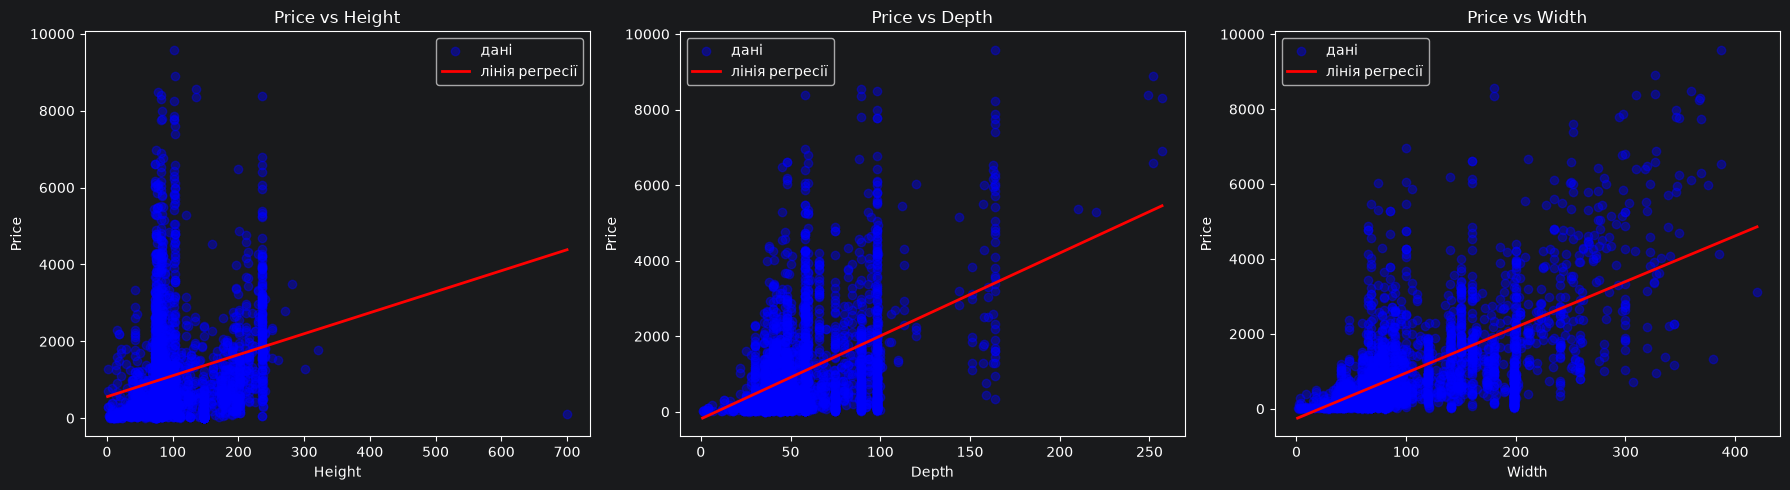

In [140]:
features = ["height", "depth", "width"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feat in enumerate(features):
    X = df_model[[feat]].values
    y = df_model["price"].values

    model = LinearRegression()
    model.fit(X, y)

    x_range = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
    y_pred = model.predict(x_range)

    axes[i].scatter(X, y, alpha=0.4, color="blue", label="дані")
    axes[i].plot(x_range, y_pred, color="red", linewidth=2, label="лінія регресії")
    axes[i].set_xlabel(feat.capitalize())
    axes[i].set_ylabel("Price")
    axes[i].set_title(f"Price vs {feat.capitalize()}")
    axes[i].legend()

plt.tight_layout()

Розміри мають певний вплив, але самі по собі не визначають ціну. Серед трьох розмірів саме ширина дає більш виражену тенденцію до зростання ціни.

In [141]:
pipeline_rf_base  = Pipeline([
    ("model", RandomForestRegressor(
        n_estimators=500,
        max_depth=12,
        min_samples_leaf=3,
        min_samples_split=6,
        random_state=42,
        n_jobs=-1
    ))
])

In [142]:
pipeline_rf_base.fit(X_train, y_train)
y_pred_rf_base = pipeline_rf_base.predict(X_test)

In [143]:
print("Test R²:", r2_score(y_test, y_pred_rf_base))
print("Test MSE:", mean_squared_error(y_test, y_pred_rf_base))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf_base)))

Test R²: 0.7421108029908329
Test MSE: 503317.2443727047
Test RMSE: 709.4485494894642


In [144]:
scores_rf_base = cross_val_score(pipeline_rf_base, X_train, y_train, cv=5, scoring="r2")
print("\nR² по фолдам:", scores_rf_base)
print("Середнє R²:", scores_rf_base.mean())


R² по фолдам: [0.7962964  0.75440059 0.71529944 0.77331466 0.79153326]
Середнє R²: 0.7661688716720574


In [145]:
importances = pipeline_rf_base.named_steps["model"].feature_importances_
features = X_train.columns
sorted(zip(features, importances), key=lambda x: x[1], reverse=True)

[('width', np.float64(0.5878488958683488)),
 ('designer_median_price', np.float64(0.15810586061399964)),
 ('depth', np.float64(0.10504737521840163)),
 ('n_designers', np.float64(0.07158362730352494)),
 ('height', np.float64(0.046109602319313894)),
 ('category_median_price', np.float64(0.02143567644953862)),
 ('other_colors', np.float64(0.00986896222687265))]

In [146]:
df_corr = df_transformed.copy()
df_corr["price"] = y
corr = df_corr.corr()
print(corr["price"].sort_values(ascending=False))

price                    1.000000
width                    0.636088
depth                    0.451808
designer_median_price    0.419920
category_median_price    0.383544
n_designers              0.318251
height                   0.229071
other_colors             0.121664
Name: price, dtype: float64


In [147]:
X_vif = df_transformed.copy()
X_vif = X_vif.astype(float)
vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print(vif.sort_values("VIF", ascending=False))

                 feature       VIF
4                  depth  6.075546
1  category_median_price  5.660162
2                  width  5.571449
6            n_designers  4.479525
3                 height  4.322534
0  designer_median_price  4.037301
5           other_colors  1.956693


(array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5]),
 [Text(0.5, 0, 'designer_median_price'),
  Text(1.5, 0, 'category_median_price'),
  Text(2.5, 0, 'width'),
  Text(3.5, 0, 'height'),
  Text(4.5, 0, 'depth'),
  Text(5.5, 0, 'other_colors'),
  Text(6.5, 0, 'n_designers'),
  Text(7.5, 0, 'price')])

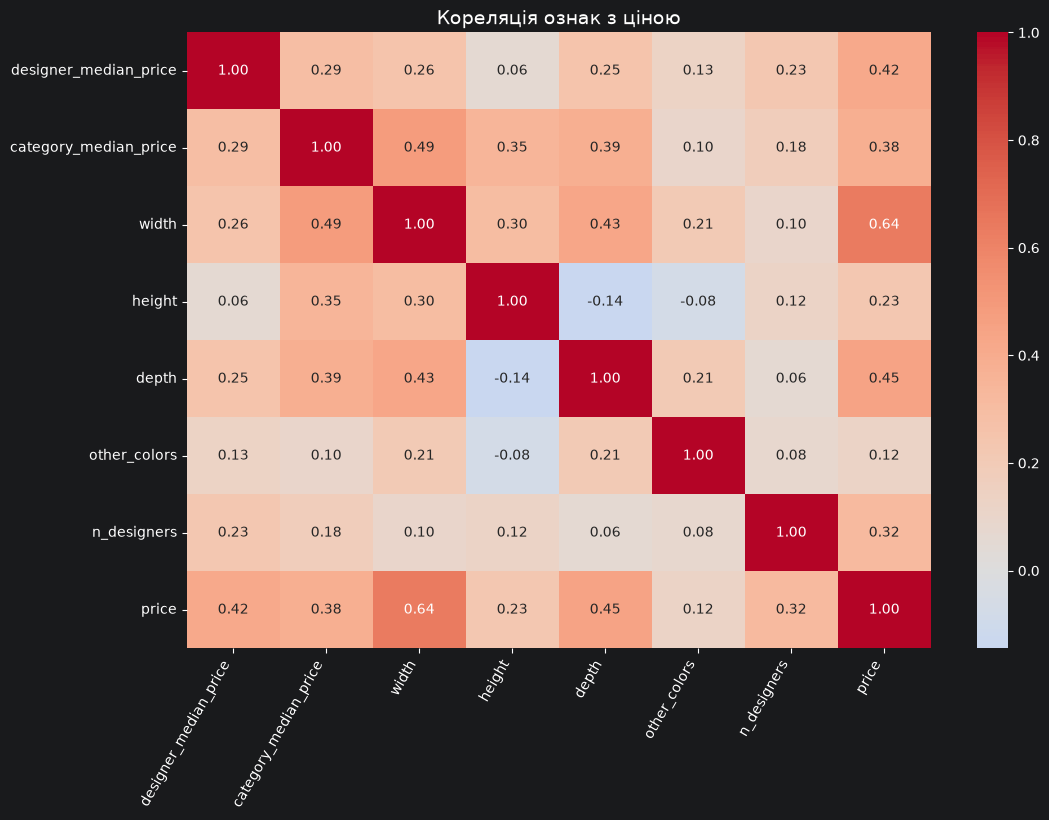

In [148]:
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Кореляція ознак з ціною", fontsize=14)

plt.xticks(rotation=60, ha="right")

Text(0.5, 1.0, 'Feature Importance')

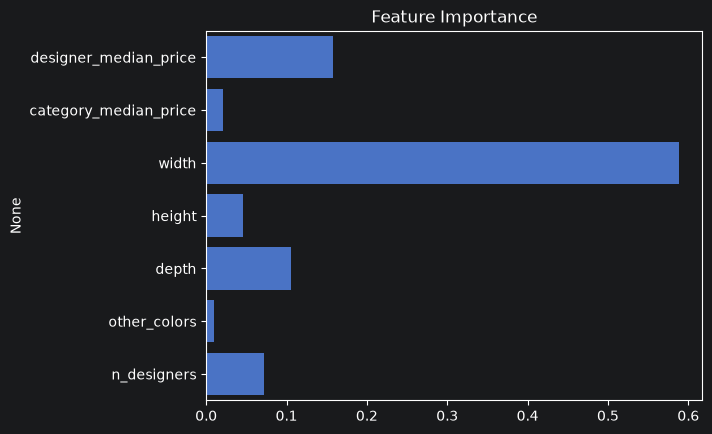

In [149]:
importances = pipeline_rf_base.named_steps["model"].feature_importances_
features = X_train.columns
sns.barplot(x=importances, y=features)
plt.title("Feature Importance")

Text(0.5, 1.0, 'Predicted vs Actual')

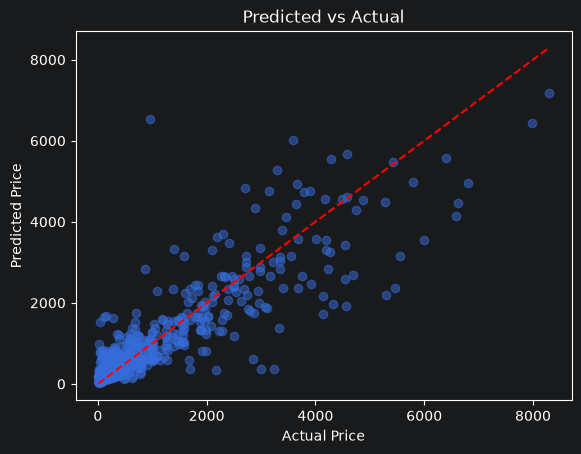

In [150]:
plt.scatter(y_test, y_pred_rf_base, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual")

Модель демонструє позитивну кореляцію між прогнозами та реальними значеннями: більшість точок близькі до лінії.
Є певні відхилення, але вони не критичні - модель має достатньо високу точність.

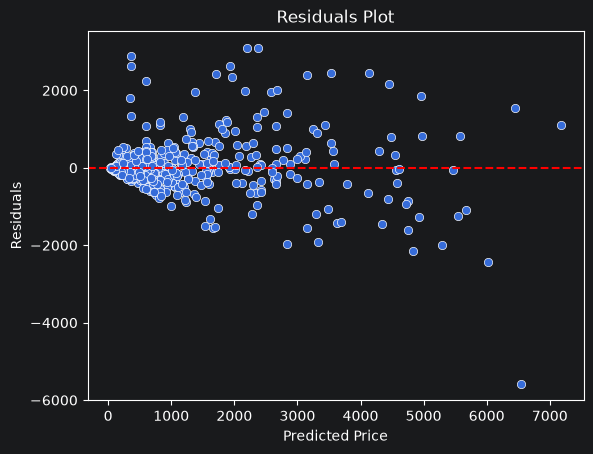

In [151]:
residuals = y_test - y_pred_rf_base
sns.scatterplot(x=y_pred_rf_base, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals Plot")
plt.show()

Модель не має систематичного зміщення — вона не завищує і не занижує прогнози в середньому. Є окремі відхилення, але вони не формують чіткої структури, тобто помилки випадкові.

In [152]:
importances = pipeline_rf_base.named_steps["model"].feature_importances_

features = X_train.columns
feature_importances = pipeline_rf_base.named_steps["model"].feature_importances_

pd.DataFrame({
    "feature": features,
    "importance": importances
}).sort_values("importance", ascending=False)


,feature,importance
2,width,0.587849
0,designer_median_price,0.158106
4,depth,0.105047
6,n_designers,0.071584
3,height,0.046110
1,category_median_price,0.021436
5,other_colors,0.009869


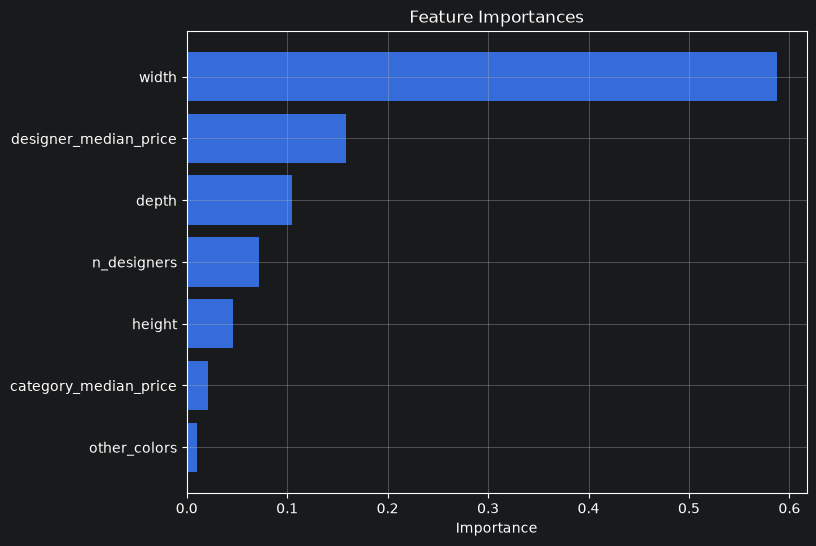

In [153]:
fi_df = pd.DataFrame({"feature": features, "importance": feature_importances}).sort_values("importance", ascending=True)

plt.figure(figsize=(8,6))
plt.barh(fi_df["feature"], fi_df["importance"])
plt.xlabel("Importance")
plt.title("Feature Importances")

plt.grid()

In [154]:
param_grid_rf = {
    "model__n_estimators": [200, 500, 800],
    "model__max_depth": [10, 12, 15],
    "model__min_samples_leaf": [2, 3, 5],
    "model__min_samples_split": [4, 6, 8]
}

In [155]:
pipeline_rf = Pipeline([
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
])

In [156]:
grid_search_rf = GridSearchCV(
    pipeline_rf,
    param_grid_rf,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=2
)

grid_search_rf.fit(X_train, y_train)
print("Найкращі параметри:", grid_search_rf.best_params_)
print("Найкращий R² (CV):", grid_search_rf.best_score_)

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Найкращі параметри: {'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__min_samples_split': 4, 'model__n_estimators': 200}
Найкращий R² (CV): 0.77291842097389


In [157]:
best_pipeline_rf = grid_search_rf.best_estimator_

In [158]:
scores_rf = cross_val_score(best_pipeline_rf, X_train, y_train, cv=5, scoring="r2")
print("R² по фолдам:", scores_rf)
print("Середнє R²:", scores_rf.mean())

R² по фолдам: [0.80549578 0.76235489 0.72483202 0.78524381 0.78666561]
Середнє R²: 0.77291842097389


In [159]:
best_pipeline_rf.fit(X_train, y_train)
y_pred_rf = best_pipeline_rf.predict(X_test)

In [160]:
print("Test R²:", r2_score(y_test, y_pred_rf))
print("Test MSE:", mean_squared_error(y_test, y_pred_rf))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Test R²: 0.7477180288179841
Test MSE: 492373.7326450812
Test RMSE: 701.6934748485845


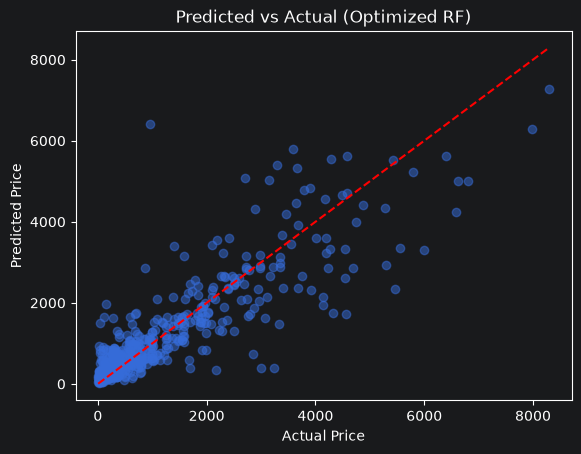

In [161]:
plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Predicted vs Actual (Optimized RF)")
plt.show()


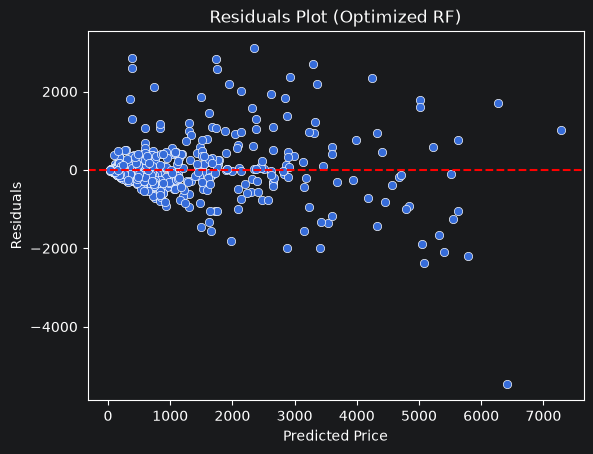

In [162]:
residuals = y_test - y_pred_rf
sns.scatterplot(x=y_pred_rf, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residuals Plot (Optimized RF)")
plt.show()


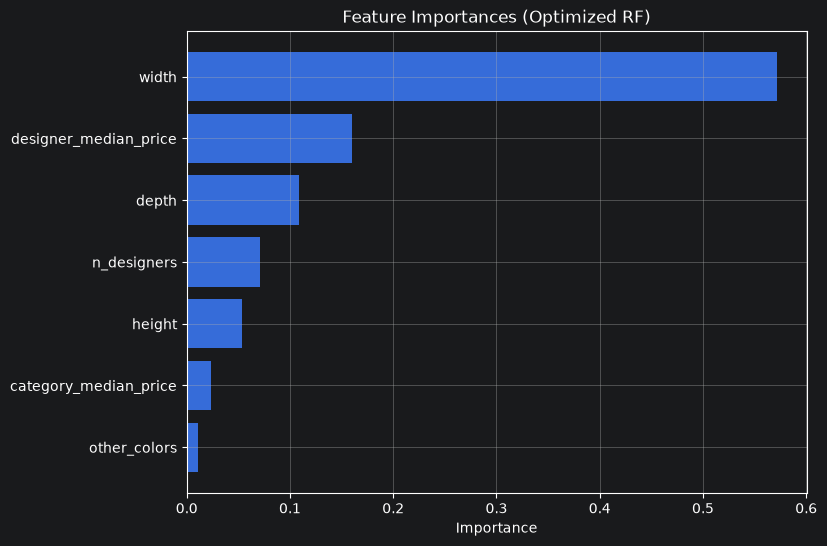

In [163]:
importances = best_pipeline_rf.named_steps["model"].feature_importances_
features = X_train.columns
fi_df = pd.DataFrame({"feature": features, "importance": importances}).sort_values("importance", ascending=True)

plt.figure(figsize=(8,6))
plt.barh(fi_df["feature"], fi_df["importance"])
plt.xlabel("Importance")
plt.title("Feature Importances (Optimized RF)")
plt.grid()
plt.show()


In [164]:
param_grid_lr = {
    "model__fit_intercept": [True, False]
}

In [165]:
pipeline_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

In [166]:
grid_search_lr = GridSearchCV(pipeline_lr, param_grid_lr, cv=5, scoring="r2")

In [167]:
grid_search_lr.fit(X_train, y_train)

print("\nНайкращі параметри:", grid_search_lr.best_params_)
print("Найкращий R² (CV):", grid_search_lr.best_score_)


Найкращі параметри: {'model__fit_intercept': True}
Найкращий R² (CV): 0.5478219383553142


In [168]:
best_pipeline_lr = grid_search_lr.best_estimator_

In [169]:
scores_lr = cross_val_score(best_pipeline_lr, X_train, y_train, cv=5, scoring="r2")
print("\nR² по фолдам:", scores_lr)
print("Середнє R²:", scores_lr.mean())


R² по фолдам: [0.54456405 0.48049852 0.49711339 0.62588221 0.59105153]
Середнє R²: 0.5478219383553142


In [170]:
best_pipeline_lr.fit(X_train, y_train)
y_pred_lr = best_pipeline_lr.predict(X_test)

In [171]:
print("Test R²:", r2_score(y_test, y_pred_lr))
print("Test MSE:", mean_squared_error(y_test, y_pred_lr))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))

Test R²: 0.5518410709862799
Test MSE: 874662.9165090232
Test RMSE: 935.2341506323554


Text(0.5, 1.0, 'LinearRegression: Predicted vs Actual')

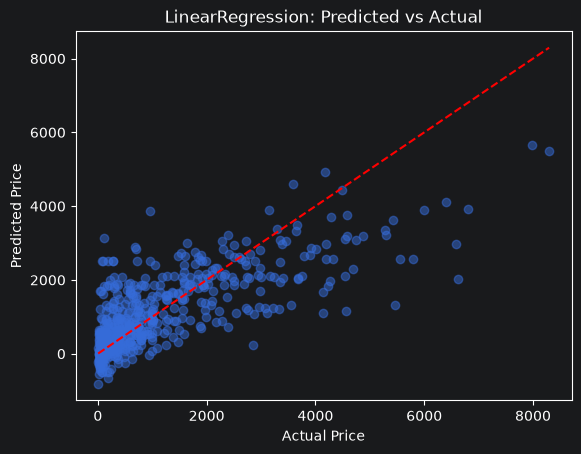

In [172]:
plt.scatter(y_test, y_pred_lr, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("LinearRegression: Predicted vs Actual")

Лінійна регресія дає адекватні результати, але для більш точного прогнозу варто використовувати моделі з гнучкішою структурою

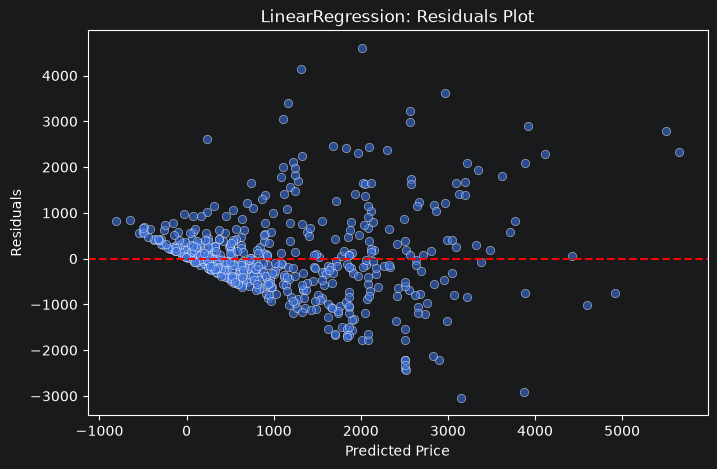

In [173]:
# залишки
residuals_lr = y_test - y_pred_lr

plt.figure(figsize=(8,5))
sns.scatterplot(x=y_pred_lr, y=residuals_lr, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("LinearRegression: Residuals Plot")
plt.show()


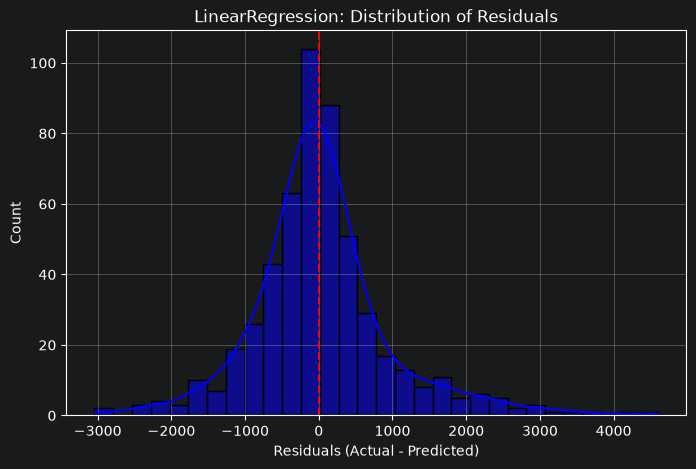

In [174]:
residuals_lr = y_test - y_pred_lr

plt.figure(figsize=(8,5))
sns.histplot(residuals_lr, bins=30, kde=True, color="blue")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Count")
plt.title("LinearRegression: Distribution of Residuals")
plt.grid()

Форма розподілу наближена до нормального, хоча є невелика асиметрія вліво — що модель іноді має тенденцію трохи занижувати значення.

In [175]:
param_grid_hgb = {
    "model__max_depth": [8, 10, 12],
    "model__learning_rate": [0.05, 0.1],
    "model__max_iter": [200, 500]
}

In [176]:
pipeline_hgb = Pipeline([
    ("model", HistGradientBoostingRegressor(random_state=42))
])

In [177]:
grid_search_hgb = GridSearchCV(pipeline_hgb, param_grid_hgb, cv=5, scoring="r2", n_jobs=-1)

In [178]:
grid_search_hgb.fit(X_train, y_train)

print("\nНайкращі параметри:", grid_search_hgb.best_params_)
print("Найкращий R²:", grid_search_hgb.best_score_)


Найкращі параметри: {'model__learning_rate': 0.05, 'model__max_depth': 10, 'model__max_iter': 500}
Найкращий R²: 0.7822628799595928


In [179]:
best_pipeline_hgb = grid_search_hgb.best_estimator_

In [180]:
scores_hgb = cross_val_score(best_pipeline_hgb, X_train, y_train, cv=5, scoring="r2")
print("\nR² по фолдам:", scores_hgb)
print("Середнє R²:", scores_hgb.mean())


R² по фолдам: [0.81644553 0.78930472 0.73797543 0.77910053 0.78848819]
Середнє R²: 0.7822628799595928


In [181]:
best_pipeline_hgb.fit(X_train, y_train)
y_pred_hgb = best_pipeline_hgb.predict(X_test)

print("Test R²:", r2_score(y_test, y_pred_hgb))
print("Test MSE:", mean_squared_error(y_test, y_pred_hgb))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_hgb)))

Test R²: 0.7372839563798226
Test MSE: 512737.70542124205
Test RMSE: 716.057054585207


Text(0.5, 1.0, 'HistGradientBoosting: Predicted vs Actual')

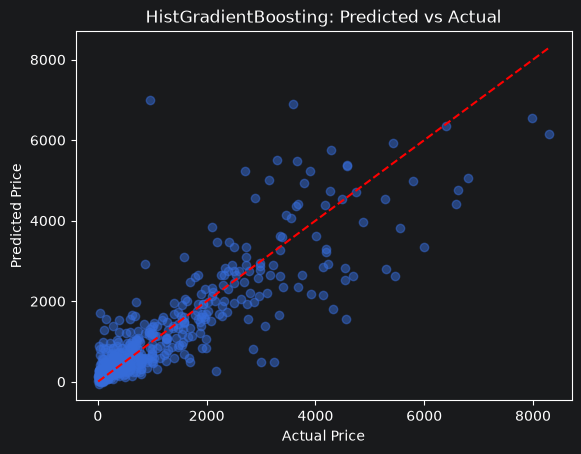

In [182]:
plt.scatter(y_test, y_pred_hgb, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("HistGradientBoosting: Predicted vs Actual")

Модель HistGradientBoosting демонструє високу якість прогнозування і є більш гнучкою, ніж проста лінійна регресія.

Text(0.5, 1.0, 'HistGradientBoosting: Residuals')

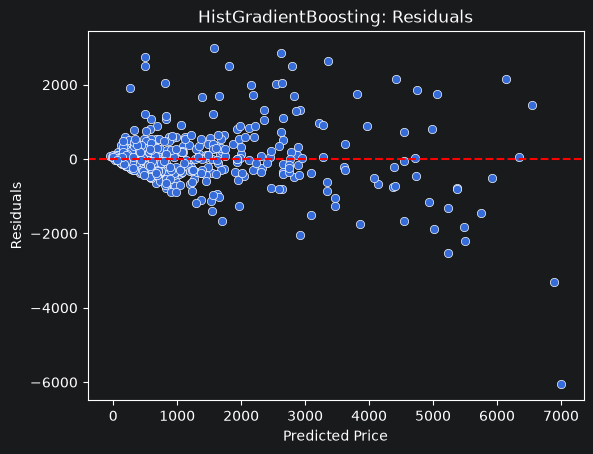

In [183]:
residuals_hgb = y_test - y_pred_hgb
sns.scatterplot(x=y_pred_hgb, y=residuals_hgb)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("HistGradientBoosting: Residuals")

Модель показує адекватну якість прогнозування: залишки розподілені випадково, без систематичних помилок.

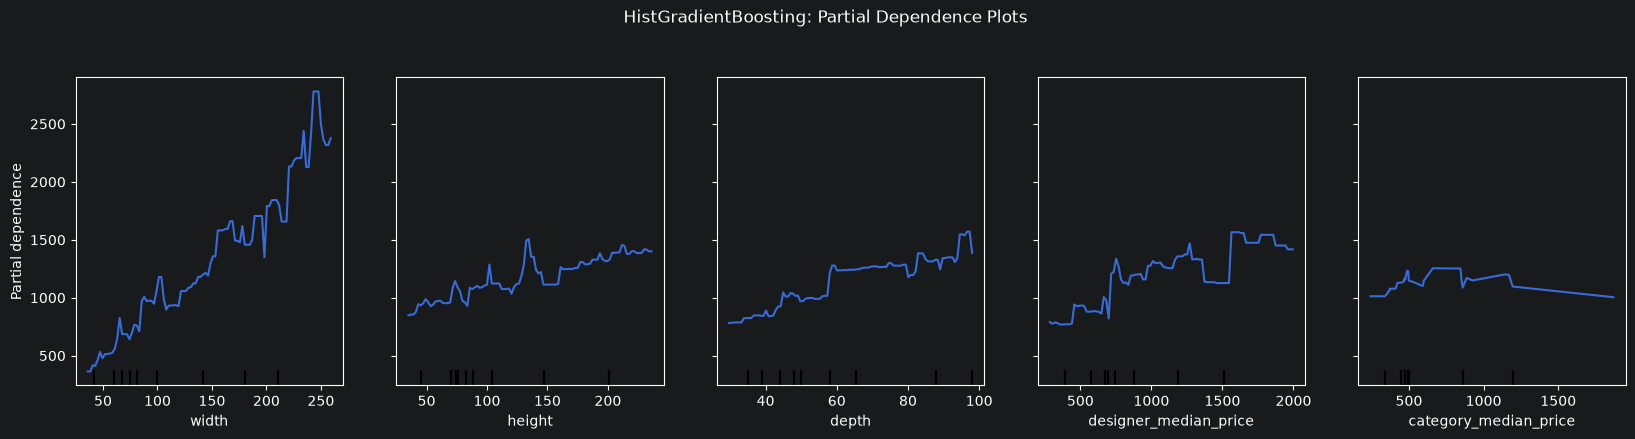

In [184]:
from sklearn.inspection import PartialDependenceDisplay

features = ["width", "height", "depth", "designer_median_price", "category_median_price"]

fig, ax = plt.subplots(figsize=(20,4))

PartialDependenceDisplay.from_estimator(
    best_pipeline_hgb, X_train,
    ["width", "height", "depth", "designer_median_price", "category_median_price"],
    kind="average",
    n_cols=5,   # всі 5 графіків в один ряд
    ax=ax
)
plt.suptitle("HistGradientBoosting: Partial Dependence Plots", y=1.05)
plt.show()


In [185]:
results = {
    "RandomForest": {
        "R2": r2_score(y_test, y_pred_rf),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        "MSE": mean_squared_error(y_test, y_pred_rf)
    },
    "LinearRegression": {
        "R2": r2_score(y_test, y_pred_lr),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        "MSE": mean_squared_error(y_test, y_pred_lr)
    },
    "HistGradientBoosting": {
        "R2": r2_score(y_test, y_pred_hgb),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_hgb)),
        "MSE": mean_squared_error(y_test, y_pred_hgb)
    }
}

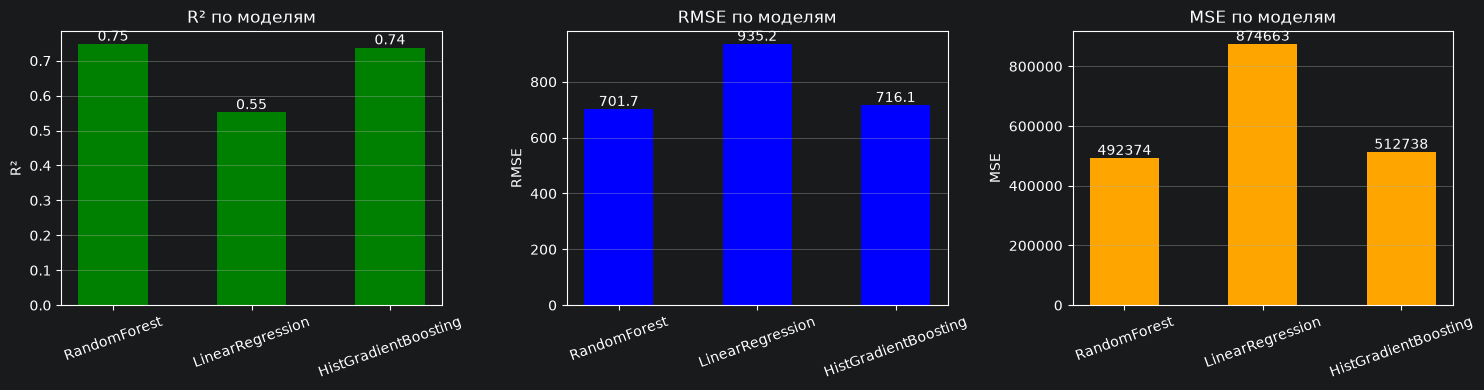

In [186]:
models = list(results.keys())
r2_values = [results[m]["R2"] for m in models]
rmse_values = [results[m]["RMSE"] for m in models]
mse_values = [results[m]["MSE"] for m in models]

x = np.arange(len(models))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- R² ---
axes[0].bar(x, r2_values, color="green", width=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=20)
axes[0].set_ylabel("R²")
axes[0].set_title("R² по моделям")
axes[0].grid(axis="y")

add_bar_labels(axes[0], fmt="%.2f", label_type="edge")

# --- RMSE ---
axes[1].bar(x, rmse_values, color="blue", width=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=20)
axes[1].set_ylabel("RMSE")
axes[1].set_title("RMSE по моделям")
axes[1].grid(axis="y")

add_bar_labels(axes[1], fmt="%.1f", label_type="edge")

# --- MSE ---
axes[2].bar(x, mse_values, color="orange", width=0.5)
axes[2].set_xticks(x)
axes[2].set_xticklabels(models, rotation=20)
axes[2].set_ylabel("MSE")
axes[2].set_title("MSE по моделям")
axes[2].grid(axis="y")

add_bar_labels(axes[2], fmt="%.0f", label_type="edge")

plt.tight_layout()

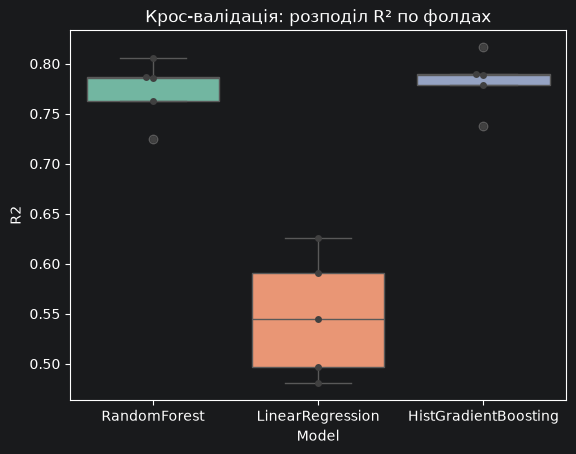

In [187]:
cv_results = {
    "Model": ["RandomForest"] * len(scores_rf) +
             ["LinearRegression"] * len(scores_lr) +
             ["HistGradientBoosting"] * len(scores_hgb),
    "R2": list(scores_rf) + list(scores_lr) + list(scores_hgb)
}

sns.boxplot(x="Model", y="R2", hue="Model", data=cv_results, palette="Set2", legend=False)
sns.swarmplot(x="Model", y="R2", data=cv_results, color=".25")
plt.title("Крос‑валідація: розподіл R² по фолдах")
plt.show()

RandomForest та HistGradientBoosting мають високі значення R² (близько 0.75–0.80) та вузький розкид, що свідчить про їхню стабільність і надійність.

Крос‑валідація підтверджує, що методи RandomForest та HistGradientBoosting краще узгоджуються з даними та забезпечують більш передбачувані результати, ніж проста лінійна регресія.

In [188]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

models = {
    "RandomForest": best_pipeline_rf,
    "LinearRegression": best_pipeline_lr,
    "HistGradientBoosting": best_pipeline_hgb
}

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "R²": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred)
    })

df_results = pd.DataFrame(results)
print(df_results)


                  Model        R²        RMSE            MSE         MAE
0          RandomForest  0.747718  701.693475  492373.732645  413.663889
1      LinearRegression  0.551841  935.234151  874662.916509  635.609379
2  HistGradientBoosting  0.737284  716.057055  512737.705421  419.147926


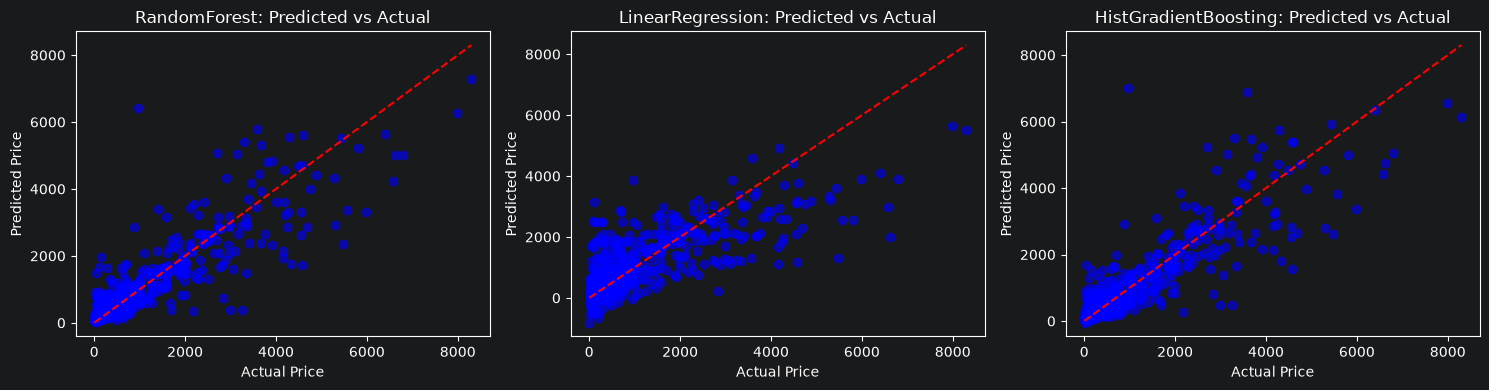

In [189]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,4))

for i, (name, model) in enumerate(models.items(), 1):
    y_pred = model.predict(X_test)
    plt.subplot(1,3,i)
    plt.scatter(y_test, y_pred, alpha=0.6, color="blue")
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    plt.xlabel("Actual Price")
    plt.ylabel("Predicted Price")
    plt.title(f"{name}: Predicted vs Actual")

plt.tight_layout()
plt.show()


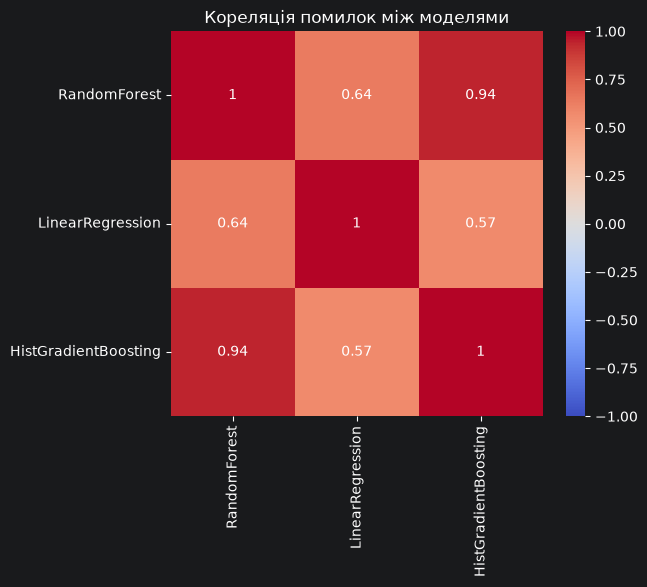

In [190]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

preds = {
    "RandomForest": best_pipeline_rf.predict(X_test),
    "LinearRegression": best_pipeline_lr.predict(X_test),
    "HistGradientBoosting": best_pipeline_hgb.predict(X_test)
}

errors = pd.DataFrame({name: y_test - y_pred for name, y_pred in preds.items()})
corr = errors.corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Кореляція помилок між моделями")
plt.show()


C:\Users\nov28\AppData\Local\Temp\ipykernel_10608\2449042688.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="Model", y="Residuals", data=errors_long, palette="Set2")


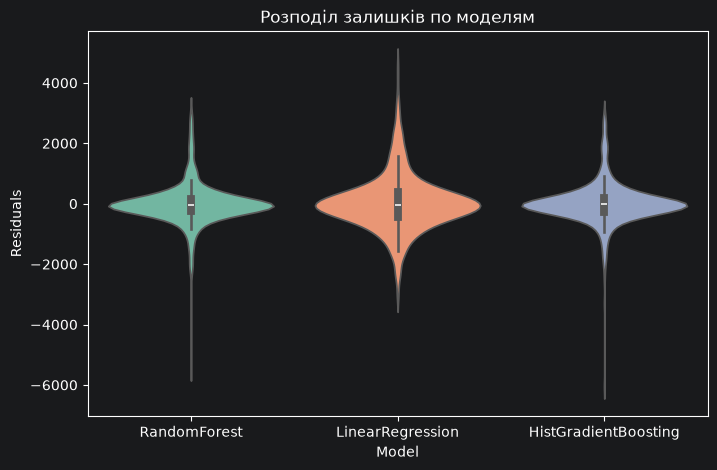

In [191]:
import seaborn as sns

errors_long = errors.melt(var_name="Model", value_name="Residuals")

plt.figure(figsize=(8,5))
sns.violinplot(x="Model", y="Residuals", data=errors_long, palette="Set2")
plt.title("Розподіл залишків по моделям")
plt.show()


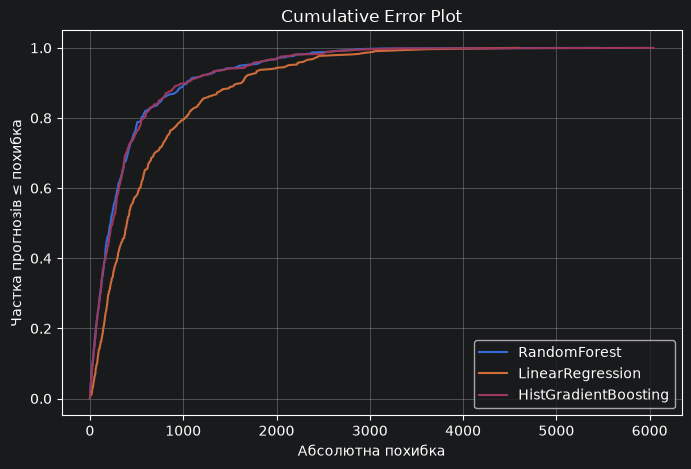

In [192]:
import numpy as np

plt.figure(figsize=(8,5))

for name, y_pred in preds.items():
    abs_errors = np.abs(y_test - y_pred)
    sorted_errors = np.sort(abs_errors)
    cum_prob = np.arange(1, len(sorted_errors)+1) / len(sorted_errors)
    plt.plot(sorted_errors, cum_prob, label=name)

plt.xlabel("Абсолютна похибка")
plt.ylabel("Частка прогнозів ≤ похибка")
plt.title("Cumulative Error Plot")
plt.legend()
plt.grid()
plt.show()


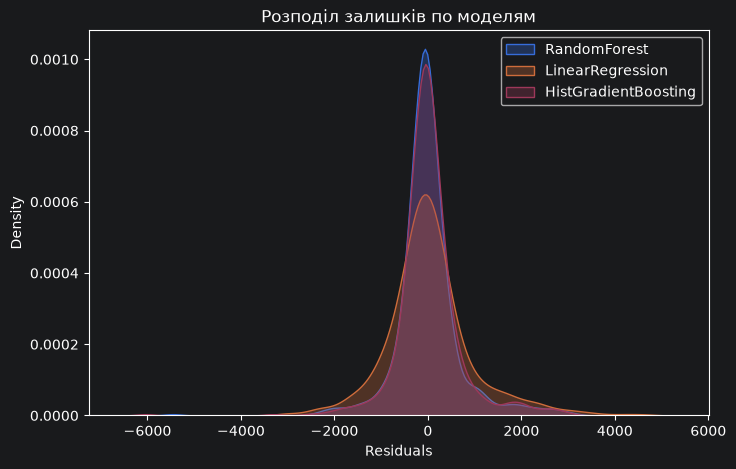

In [193]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
for name, y_pred in preds.items():
    sns.kdeplot(y_test - y_pred, label=name, fill=True, alpha=0.3)

plt.xlabel("Residuals")
plt.ylabel("Density")
plt.title("Розподіл залишків по моделям")
plt.legend()
plt.show()


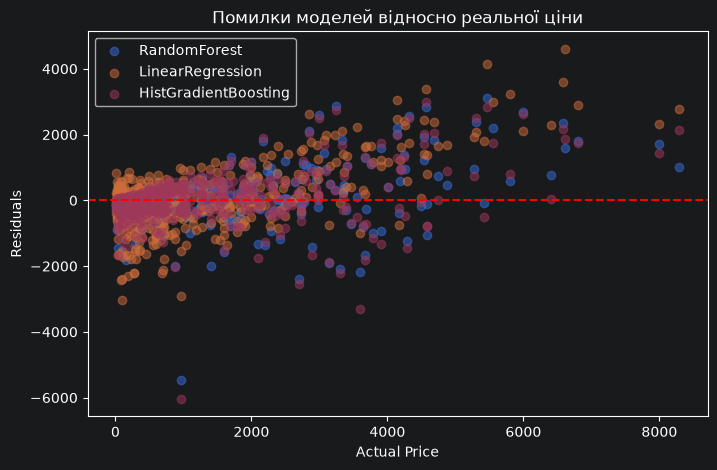

In [194]:
plt.figure(figsize=(8,5))
for name, y_pred in preds.items():
    plt.scatter(y_test, y_test - y_pred, alpha=0.5, label=name)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual Price")
plt.ylabel("Residuals")
plt.title("Помилки моделей відносно реальної ціни")
plt.legend()
plt.show()


C:\Users\nov28\AppData\Local\Temp\ipykernel_10608\1707108365.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Model", y="Absolute Error", data=abs_errors_long, palette="Set3")


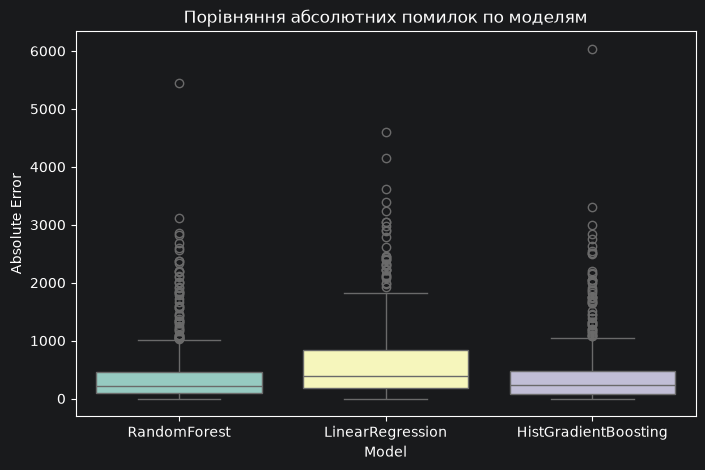

In [195]:
import pandas as pd

abs_errors = pd.DataFrame({name: abs(y_test - y_pred) for name, y_pred in preds.items()})
abs_errors_long = abs_errors.melt(var_name="Model", value_name="Absolute Error")

plt.figure(figsize=(8,5))
sns.boxplot(x="Model", y="Absolute Error", data=abs_errors_long, palette="Set3")
plt.title("Порівняння абсолютних помилок по моделям")
plt.show()
